# EcoRoute Rurale V4 — no Overpass or public map tiles
Download a Morocco OSM snapshot once, then extract settlements and roads locally. Run cells in order. Internet is needed only for initial downloads. If automatic downloads fail, place the files in `ecoroute_data` manually. Road speeds and access are approximate, not verified truck routing.

Maps use local vector overlays only. Folium JavaScript/CSS may still load from CDNs; this is not a fully offline browser bundle.

In [2]:
%pip install osmium geopandas networkx scipy folium ipywidgets requests pandas

Defaulting to user installation because normal site-packages is not writeable
  Using cached osmium-4.3.2-cp314-cp314-win_amd64.whl.metadata (3.7 kB)
  Using cached geopandas-1.2.0-py3-none-any.whl.metadata (2.0 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
  Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl.metadata (61 kB)
  Using cached folium-1.0.0-py2.py3-none-any.whl.metadata (4.1 kB)
  Using cached ipywidgets-8.1.9-py3-none-any.whl.metadata (2.4 kB)
  Using cached pyogrio-0.13.0-cp311-abi3-win_amd64.whl.metadata (6.0 kB)
  Using cached pyproj-3.8.0-cp314-cp314-win_amd64.whl.metadata (40 kB)
  Using cached branca-0.8.2-py3-none-any.whl.metadata (1.7 kB)
  Using cached jupyterlab_widgets-3.0.17-py3-none-any.whl.metadata (20 kB)
Using cached osmium-4.3.2-cp314-cp314-win_amd64.whl (1.9 MB)
Using cached geopandas-1.2.0-py3-none-any.whl (368 kB)
Using cached networkx-3.7-py3-none-any.whl (2.1 MB)
Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl (37.4 MB)
Usin

In [ ]:
from pathlib import Path
import requests, json, math, os
import pandas as pd
import geopandas as gpd
import networkx as nx
import numpy as np
import osmium
import folium
import ipywidgets as widgets
from shapely.geometry import Point, shape
from shapely.prepared import prep
from scipy.spatial import cKDTree
from IPython.display import display
OUT = Path('ecoroute_data'); OUT.mkdir(exist_ok=True)
PBF = OUT / 'morocco-latest.osm.pbf'
BOUNDARY = OUT / 'boundary.geojson'
BUFFER_M = 5000
URL = 'https://download.geofabrik.de/africa/morocco-latest.osm.pbf'


In [39]:
# Download once; incomplete downloads are never treated as finished.
if not PBF.exists():
    tmp = PBF.with_suffix('.part')
    try:
        with requests.get(URL, stream=True, timeout=(15, 90)) as r:
            r.raise_for_status()
            total = int(r.headers.get('Content-Length', 0))
            done = 0
            with tmp.open('wb') as f:
                for chunk in r.iter_content(1024*1024):
                    f.write(chunk); done += len(chunk)
                    if done // (20*1024**2) != (done-len(chunk)) // (20*1024**2):
                        print(f'{done/1024**2:.0f} MB downloaded', flush=True)
            if total and done != total:
                raise IOError('Incomplete download')
        tmp.replace(PBF)
    except Exception as e:
        raise RuntimeError(f'Download failed. Download {URL} in your browser and save as {PBF}') from e
print(f'Local snapshot: {PBF.stat().st_size/1024**2:.1f} MB')

Local snapshot: 233.4 MB


In [40]:
# Reuse the original notebook boundary if present; otherwise use Nominatim once.
if not BOUNDARY.exists():
    r = requests.get('https://nominatim.openstreetmap.org/search',
        params={'q':'Chefchaouen Province, Morocco','format':'jsonv2','polygon_geojson':1,'limit':5},
        headers={'User-Agent':'EcoRouteRurale-student-MVP/3.0'}, timeout=(10,40))
    r.raise_for_status()
    candidates = [x for x in r.json() if x.get('geojson',{}).get('type') in ('Polygon','MultiPolygon') and x.get('type')=='administrative']
    if not candidates:
        raise RuntimeError('No administrative polygon found. Supply a verified province boundary.geojson manually.')
    hit = candidates[0]
    print('Verify this boundary:', hit['display_name'])
    gpd.GeoDataFrame({'name':[hit['display_name']]},geometry=[shape(hit['geojson'])],crs=4326).to_file(BOUNDARY,driver='GeoJSON')
boundary = gpd.read_file(BOUNDARY).to_crs(4326)
polygon = boundary.geometry.unary_union
utm = boundary.estimate_utm_crs()
buffered = boundary.to_crs(utm).geometry.buffer(BUFFER_M).to_crs(4326).unary_union
inside = prep(polygon); road_area = prep(buffered)
print(boundary.drop(columns='geometry'))
m = folium.Map(location=[polygon.centroid.y,polygon.centroid.x],zoom_start=9, tiles=None)
folium.GeoJson(boundary).add_to(m)
m.fit_bounds([[polygon.bounds[1], polygon.bounds[0]], [polygon.bounds[3], polygon.bounds[2]]])
from branca.element import Element
def add_attribution(m):
    m.get_root().html.add_child(Element('<div style="position:absolute;bottom:5px;right:5px;z-index:9999;background:white;padding:4px">© <a href="https://www.openstreetmap.org/copyright">OpenStreetMap contributors</a></div>'))
add_attribution(m); display(m)

C:\Users\pc gold\AppData\Local\Temp\ipykernel_3888\4143525912.py:14: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  polygon = boundary.geometry.unary_union


                                                name
0  Province de Chefchaouen ⵜⵛⴻⴼⵜⵛⴰⵡⴻⵏ إقليم شفشاو...


C:\Users\pc gold\AppData\Local\Temp\ipykernel_3888\4143525912.py:16: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  buffered = boundary.to_crs(utm).geometry.buffer(BUFFER_M).to_crs(4326).unary_union


In [42]:
# Local settlement extraction; no API calls.
class Settlements(osmium.SimpleHandler):
    def __init__(self):
        super().__init__(); self.rows=[]
    def node(self,n):
        if n.tags.get('place') not in ('village','hamlet') or not n.tags.get('name') or not n.location.valid(): return
        x,y=n.location.lon,n.location.lat
        p=Point(x,y)
        if inside.contains(p):
            self.rows.append(dict(osm_id=f'node/{n.id}',name=n.tags['name'],place=n.tags['place'],latitude=y,longitude=x,geometry=p))
s=Settlements(); s.apply_file(str(PBF))
if not s.rows: raise RuntimeError('No named settlement nodes found; verify boundary.')
douars=gpd.GeoDataFrame(s.rows,crs=4326).sort_values('name').drop_duplicates('osm_id').reset_index(drop=True)
douars.to_file(OUT/'douars.geojson',driver='GeoJSON')
douars.drop(columns='geometry').to_csv(OUT/'douars.csv',index=False)
print(len(douars),'settlement candidates'); display(douars.head(20))

DataSourceError: Failed to create GeoJSON datasource: \content\ecoroute_data\douars.geojson: 

In [ ]:
def make_map(ids=()):
    m=folium.Map(location=[polygon.centroid.y,polygon.centroid.x],zoom_start=10, tiles=None)
    folium.GeoJson(boundary).add_to(m)
    for r in douars.itertuples():
        folium.CircleMarker([r.latitude,r.longitude],radius=5,color='green' if r.osm_id in ids else 'blue',tooltip=r.name,fill=True).add_to(m)
    if "G" in globals() and G.number_of_edges():
        from shapely.geometry import LineString, mapping
        features = []
        seen = set()
        for u,v,k,d in G.edges(keys=True,data=True):
            key = tuple(sorted((u,v)))
            if key in seen: continue
            seen.add(key)
            a,b = G.nodes[u],G.nodes[v]
            features.append({"type":"Feature","properties":{},"geometry":mapping(LineString([(a["x"],a["y"]),(b["x"],b["y"])]))})
        folium.GeoJson({"type":"FeatureCollection","features":features},name="Local roads",show=False,style_function=lambda _: {"color":"#777777","weight":1}).add_to(m)
        folium.LayerControl().add_to(m)
    m.fit_bounds([[polygon.bounds[1],polygon.bounds[0]],[polygon.bounds[3],polygon.bounds[2]]])
    add_attribution(m)
    return m
display(make_map())
picker=widgets.SelectMultiple(options=[(f'{r.name} ({r.osm_id})',r.osm_id) for r in douars.itertuples()],rows=15,layout=widgets.Layout(width='95%'))
button=widgets.Button(description='Save selection'); output=widgets.Output()
def save(_):
    with output:
        output.clear_output()
        selected=douars[douars.osm_id.isin(picker.value)]
        if selected.empty: print('Select at least one douar'); return
        selected.drop(columns='geometry').to_csv(OUT/'selected_douars.csv',index=False)
        display(make_map(set(picker.value))); print(len(selected),'saved')
button.on_click(save); display(picker,button,output)

In [ ]:
# Local directed road graph. Approximate motor-vehicle access and speeds.
SPEEDS={'motorway':100,'trunk':80,'primary':65,'secondary':50,'tertiary':40,'unclassified':30,'residential':25,'living_street':10,'service':15,'track':12}
ALLOW_TRACKS=True
G=nx.MultiDiGraph(crs='EPSG:4326')
def meters(x1,y1,x2,y2):
    a,b=math.radians(y1),math.radians(y2)
    h=math.sin((b-a)/2)**2+math.cos(a)*math.cos(b)*math.sin(math.radians(x2-x1)/2)**2
    return 12742000*math.asin(min(1,math.sqrt(h)))
class Roads(osmium.SimpleHandler):
    def way(self,w):
        t=w.tags; kind=t.get('highway')
        base=kind.removesuffix('_link') if kind else ''
        if base not in SPEEDS or (base=='track' and not ALLOW_TRACKS): return
        access=t.get('motorcar',t.get('motor_vehicle',t.get('vehicle',t.get('access','yes'))))
        if access in ('no','private','agricultural','forestry'): return
        speed=SPEEDS[base]
        try: speed=min(speed,float(t.get('maxspeed','').split()[0]))
        except (ValueError,IndexError): pass
        if speed<=0: speed=SPEEDS[base]
        if t.get('surface') in ('dirt','ground','gravel','unpaved','sand'): speed=min(speed,15)
        direction=t.get('oneway', 'yes' if t.get('junction')=='roundabout' or base=='motorway' else 'no')
        prev=None
        for node in w.nodes:
            if not node.location.valid(): prev=None; continue
            x,y=node.lon,node.lat
            if not road_area.covers(Point(x,y)): prev=None; continue
            cur=(node.ref,x,y)
            if prev:
                a,ax,ay=prev; b,bx,by=cur
                length=meters(ax,ay,bx,by)
                G.add_node(a,x=ax,y=ay); G.add_node(b,x=bx,y=by)
                attrs=dict(length=length,travel_time=length/(speed/3.6),highway=kind,osmid=w.id)
                if direction!='-1': G.add_edge(a,b,**attrs)
                if direction not in ('yes','1','true'): G.add_edge(b,a,**attrs)
            prev=cur
roads=Roads(); roads.apply_file(str(PBF),locations=True,idx='flex_mem')
if not G.number_of_nodes(): raise RuntimeError('No roads found; check boundary.')
nx.write_graphml(G,OUT/'roads.graphml')
print(G.number_of_nodes(),'nodes;',G.number_of_edges(),'edges')

In [ ]:
# Refresh the interactive map after local road extraction.
display(make_map(set(picker.value)))

In [10]:
# Select 10 nearby real douars for testing

center = douars.geometry.iloc[0]

projected = douars.to_crs(utm)
center_projected = projected.geometry.iloc[0]

distances = projected.geometry.distance(center_projected)

selected = douars.loc[
    distances.nsmallest(10).index
].copy()

selected.drop(columns="geometry").to_csv(
    OUT / "selected_douars.csv",
    index=False
)

display(selected)
print("Selection saved successfully!")

,osm_id,name,place,latitude,longitude,geometry
0,node/14140912502,Aabaïdine اعبايدن,hamlet,35.073852,-4.966840,POINT (-4.96684 35.07385)
637,node/14140893592,Tajaïelt تجايلت,hamlet,35.077975,-4.960224,POINT (-4.96022 35.07798)
360,node/13592990910,Ezlaïma ازلايمة,hamlet,35.069907,-4.953375,POINT (-4.95337 35.06991)
666,node/14140912223,Talmate تلمات,hamlet,35.084811,-4.955779,POINT (-4.95578 35.08481)
516,node/13605620202,Mongoch مونكوش,hamlet,35.086484,-4.977324,POINT (-4.97732 35.08648)
638,node/13964798855,Tajensa تجنزة,hamlet,35.076390,-4.943119,POINT (-4.94312 35.07639)
348,node/13592990911,El Ouadine الواديين,hamlet,35.092454,-4.981441,POINT (-4.98144 35.09245)
131,node/13592990912,Asfourite عصفورت,hamlet,35.090970,-4.992653,POINT (-4.99265 35.09097)
1007,node/13512384833,يسك,hamlet,35.057882,-4.995003,POINT (-4.995 35.05788)
431,node/14140893598,Ikhelladine إخلادن,hamlet,35.100076,-4.981740,POINT (-4.98174 35.10008)


Selection saved successfully!


In [11]:
# Snap to nearest road in projected meters, then calculate directed matrices.
selection=OUT/'selected_douars.csv'
if not selection.exists(): raise FileNotFoundError('Select douars and click Save selection first.')
selected=pd.read_csv(selection)
if selected.empty: raise ValueError('Empty selection')
if not set(selected.osm_id).issubset(set(douars.osm_id)): raise ValueError('Stale selection; save again.')
ids=list(G.nodes)
road_points=gpd.GeoSeries([Point(G.nodes[i]['x'],G.nodes[i]['y']) for i in ids],crs=4326).to_crs(utm)
query_points=gpd.GeoSeries(gpd.points_from_xy(selected.longitude,selected.latitude),crs=4326).to_crs(utm)
tree=cKDTree(np.column_stack([road_points.x,road_points.y]))
dist,idx=tree.query(np.column_stack([query_points.x,query_points.y]))
selected['road_node']=[ids[i] for i in idx]; selected['snap_distance_m']=dist
labels=selected.osm_id.tolist(); km=pd.DataFrame(np.inf,index=labels,columns=labels); minutes=km.copy()
for a in selected.itertuples():
    d=nx.single_source_dijkstra_path_length(G,a.road_node,weight='length')
    t=nx.single_source_dijkstra_path_length(G,a.road_node,weight='travel_time')
    for b in selected.itertuples():
        km.loc[a.osm_id,b.osm_id]=d.get(b.road_node,np.inf)/1000
        minutes.loc[a.osm_id,b.osm_id]=t.get(b.road_node,np.inf)/60
km.to_csv(OUT/'distance_km.csv'); minutes.to_csv(OUT/'travel_minutes.csv')
selected.to_csv(OUT/'selected_with_road_nodes.csv',index=False)
display(selected); display(km)
print('Unreachable directed pairs:',np.isinf(km.to_numpy()).sum())
print('Snaps over 500 m:',(dist>500).sum())

,osm_id,name,place,latitude,longitude,road_node,snap_distance_m
0,node/14140912502,Aabaïdine اعبايدن,hamlet,35.073852,-4.966840,6877661375,97.056794
1,node/14140893592,Tajaïelt تجايلت,hamlet,35.077975,-4.960224,1494306888,20.835890
2,node/13592990910,Ezlaïma ازلايمة,hamlet,35.069907,-4.953375,6877786823,87.678207
3,node/14140912223,Talmate تلمات,hamlet,35.084811,-4.955779,6877639051,31.621861
4,node/13605620202,Mongoch مونكوش,hamlet,35.086484,-4.977324,1494307136,169.096139
5,node/13964798855,Tajensa تجنزة,hamlet,35.076390,-4.943119,6857361101,7.639824
6,node/13592990911,El Ouadine الواديين,hamlet,35.092454,-4.981441,6878164901,35.701461
7,node/13592990912,Asfourite عصفورت,hamlet,35.090970,-4.992653,6878137288,19.325505
8,node/13512384833,يسك,hamlet,35.057882,-4.995003,6877878811,49.167723
9,node/14140893598,Ikhelladine إخلادن,hamlet,35.100076,-4.981740,6878199412,70.999788


,node/14140912502,node/14140893592,node/13592990910,node/14140912223,node/13605620202,node/13964798855,node/13592990911,node/13592990912,node/13512384833,node/14140893598
node/14140912502,0.000000,5.051505,8.639694,5.396732,2.736049,8.761138,6.187302,6.021177,7.863334,9.371145
node/14140893592,5.051505,0.000000,3.588188,2.407963,2.315456,3.709632,3.905598,6.903164,9.213900,10.253132
node/13592990910,8.639694,3.588188,0.000000,5.996151,5.903644,1.634808,7.493786,10.491352,12.802088,13.841320
node/14140912223,5.396732,2.407963,5.996151,0.000000,2.660683,6.117595,3.249954,6.247520,9.559127,9.597488
node/13605620202,2.736049,2.315456,5.903644,2.660683,0.000000,6.025089,3.451253,4.842729,6.898444,8.192696
node/13964798855,8.761138,3.709632,1.634808,6.117595,6.025089,0.000000,7.615230,10.612796,12.923533,13.878084
node/13592990911,6.187302,3.905598,7.493786,3.249954,3.451253,7.615230,0.000000,3.931160,7.749531,7.281128
node/13592990912,6.021177,6.903164,10.491352,6.247520,4.842729,10.612796,3.931160,0.000000,6.594532,4.655601
node/13512384833,7.863334,9.213900,12.802088,9.559127,6.898444,12.923533,7.749531,6.594532,0.000000,9.944500
node/14140893598,9.371145,10.253132,13.841320,9.597488,8.192696,13.878084,7.281128,4.655601,9.944500,0.000000


Unreachable directed pairs: 0
Snaps over 500 m: 0


In [12]:
import pandas as pd
import numpy as np
from itertools import combinations

selected = pd.read_csv(
    OUT / "selected_with_road_nodes.csv"
)

D = pd.read_csv(
    OUT / "distance_km.csv",
    index_col=0
)

ids = selected["osm_id"].tolist()

D = D.loc[ids, ids]

names = selected.set_index("osm_id")["name"]

print("Number of douars:", len(selected))
print("Matrix shape:", D.shape)
print("Unreachable pairs:", np.isinf(D.values).sum())

display(
    D.rename(index=names, columns=names).round(2)
)

Number of douars: 10
Matrix shape: (10, 10)
Unreachable pairs: 0


,Aabaïdine اعبايدن,Tajaïelt تجايلت,Ezlaïma ازلايمة,Talmate تلمات,Mongoch مونكوش,Tajensa تجنزة,El Ouadine الواديين,Asfourite عصفورت,يسك,Ikhelladine إخلادن
Aabaïdine اعبايدن,0.00,5.05,8.64,5.40,2.74,8.76,6.19,6.02,7.86,9.37
Tajaïelt تجايلت,5.05,0.00,3.59,2.41,2.32,3.71,3.91,6.90,9.21,10.25
Ezlaïma ازلايمة,8.64,3.59,0.00,6.00,5.90,1.63,7.49,10.49,12.80,13.84
Talmate تلمات,5.40,2.41,6.00,0.00,2.66,6.12,3.25,6.25,9.56,9.60
Mongoch مونكوش,2.74,2.32,5.90,2.66,0.00,6.03,3.45,4.84,6.90,8.19
Tajensa تجنزة,8.76,3.71,1.63,6.12,6.03,0.00,7.62,10.61,12.92,13.88
El Ouadine الواديين,6.19,3.91,7.49,3.25,3.45,7.62,0.00,3.93,7.75,7.28
Asfourite عصفورت,6.02,6.90,10.49,6.25,4.84,10.61,3.93,0.00,6.59,4.66
يسك,7.86,9.21,12.80,9.56,6.90,12.92,7.75,6.59,0.00,9.94
Ikhelladine إخلادن,9.37,10.25,13.84,9.60,8.19,13.88,7.28,4.66,9.94,0.00


In [13]:
# Maximum distance from a douar to a collection point
MAX_DISTANCE_KM = 3.0

# Preferred number of collection points
K = 3

print("Maximum farmer travel:", MAX_DISTANCE_KM, "km")
print("Preferred collection points:", K)

Maximum farmer travel: 3.0 km
Preferred collection points: 3


In [ ]:
best_centers = None
best_cost = np.inf

for k in range(K, len(ids) + 1):

    for centers in combinations(ids, k):

        distances = D.loc[:, list(centers)]

        nearest = distances.min(axis=1)

        # Respect the maximum travel constraint
        if (nearest > MAX_DISTANCE_KM).any():
            continue

        cost = nearest.sum()

        if cost < best_cost:
            best_cost = cost
            best_centers = centers

    if best_centers is not None:
        break

if best_centers is None:
    raise ValueError("No feasible solution found.")

print("Collection points:", len(best_centers))
print("Total farmer distance:", round(best_cost, 2), "km")

for i, center in enumerate(best_centers, 1):
    print(f"Point {i}: {names[center]}")

In [15]:
distances = D.loc[:, list(best_centers)]

assignments = distances.idxmin(axis=1)

results = pd.DataFrame({
    "osm_id": ids,
    "douar": names.loc[ids].values,
    "collection_id": assignments.loc[ids].values,
    "distance_km": distances.min(axis=1).loc[ids].values
})

results["collection_point"] = (
    results["collection_id"].map(names)
)

cluster_ids = {
    center: i + 1
    for i, center in enumerate(best_centers)
}

results["cluster"] = (
    results["collection_id"].map(cluster_ids)
)

results = results.sort_values("cluster")

display(results.round(2))

results.to_csv(
    OUT / "clustering_results.csv",
    index=False
)

,osm_id,douar,collection_id,distance_km,collection_point,cluster
2,node/13592990910,Ezlaïma ازلايمة,node/13592990910,0.00,Ezlaïma ازلايمة,1
5,node/13964798855,Tajensa تجنزة,node/13592990910,1.63,Ezlaïma ازلايمة,1
1,node/14140893592,Tajaïelt تجايلت,node/13605620202,2.32,Mongoch مونكوش,2
0,node/14140912502,Aabaïdine اعبايدن,node/13605620202,2.74,Mongoch مونكوش,2
3,node/14140912223,Talmate تلمات,node/13605620202,2.66,Mongoch مونكوش,2
4,node/13605620202,Mongoch مونكوش,node/13605620202,0.00,Mongoch مونكوش,2
6,node/13592990911,El Ouadine الواديين,node/13592990911,0.00,El Ouadine الواديين,3
7,node/13592990912,Asfourite عصفورت,node/13592990912,0.00,Asfourite عصفورت,4
8,node/13512384833,يسك,node/13512384833,0.00,يسك,5
9,node/14140893598,Ikhelladine إخلادن,node/14140893598,0.00,Ikhelladine إخلادن,6


In [16]:
summary = results.groupby("cluster").agg(
    collection_point=("collection_point", "first"),
    number_of_douars=("douar", "count"),
    average_distance_km=("distance_km", "mean"),
    max_distance_km=("distance_km", "max"),
    total_distance_km=("distance_km", "sum")
)

display(summary.round(2))

print(
    "Average farmer travel:",
    round(results["distance_km"].mean(), 2),
    "km"
)

print(
    "Maximum farmer travel:",
    round(results["distance_km"].max(), 2),
    "km"
)

print(
    "Single-douar collection points:",
    (summary["number_of_douars"] == 1).sum()
)

,collection_point,number_of_douars,average_distance_km,max_distance_km,total_distance_km
cluster,,,,,
1,Ezlaïma ازلايمة,2,0.82,1.63,1.63
2,Mongoch مونكوش,4,1.93,2.74,7.71
3,El Ouadine الواديين,1,0.00,0.00,0.00
4,Asfourite عصفورت,1,0.00,0.00,0.00
5,يسك,1,0.00,0.00,0.00
6,Ikhelladine إخلادن,1,0.00,0.00,0.00


Average farmer travel: 0.93 km
Maximum farmer travel: 2.74 km
Single-douar collection points: 4


In [17]:
comparison = []

for radius in [1, 2, 3, 4, 5, 6, 7, 8]:

    for k in range(1, len(ids) + 1):

        best = None

        for centers in combinations(ids, k):

            nearest = D.loc[:, list(centers)].min(axis=1)

            if (nearest > radius).any():
                continue

            cost = nearest.sum()

            if best is None or cost < best["total_distance_km"]:
                best = {
                    "radius_km": radius,
                    "collection_points": k,
                    "total_distance_km": cost,
                    "average_distance_km": nearest.mean(),
                    "max_distance_km": nearest.max(),
                    "stops_reduction_pct": 100 * (1 - k / len(ids))
                }

        if best is not None:
            comparison.append(best)
            break

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(2))

,radius_km,collection_points,total_distance_km,average_distance_km,max_distance_km,stops_reduction_pct
0,1,10,0.00,0.00,0.00,0.0
1,2,9,1.63,0.16,1.63,10.0
2,3,6,9.35,0.93,2.74,40.0
3,4,5,12.80,1.28,3.45,50.0
4,5,4,17.45,1.75,4.66,60.0
5,6,3,25.63,2.56,5.05,70.0
6,7,2,32.23,3.22,6.59,80.0
7,8,1,50.86,5.09,7.75,90.0


In [18]:
N_NEIGHBORS = 3

isolation = selected[["osm_id", "name"]].copy()

neighbor_distances = []

for douar_id in isolation["osm_id"]:

    distances = D.loc[douar_id].drop(douar_id)

    nearest = distances.nsmallest(N_NEIGHBORS)

    neighbor_distances.append(nearest.mean())

isolation["neighbor_distance_km"] = neighbor_distances

display(isolation.round(2))

,osm_id,name,neighbor_distance_km
0,node/14140912502,Aabaïdine اعبايدن,4.39
1,node/14140893592,Tajaïelt تجايلت,2.77
2,node/13592990910,Ezlaïma ازلايمة,3.71
3,node/14140912223,Talmate تلمات,2.77
4,node/13605620202,Mongoch مونكوش,2.57
5,node/13964798855,Tajensa تجنزة,3.79
6,node/13592990911,El Ouadine الواديين,3.54
7,node/13592990912,Asfourite عصفورت,4.48
8,node/13512384833,يسك,7.08
9,node/14140893598,Ikhelladine إخلادن,6.71


In [19]:
def normalize(series):

    minimum = series.min()
    maximum = series.max()

    if maximum == minimum:
        return series * 0

    return (series - minimum) / (maximum - minimum)


isolation["isolation_score"] = normalize(
    isolation["neighbor_distance_km"]
)

isolation["isolation_score_pct"] = (
    isolation["isolation_score"] * 100
)

isolation = isolation.sort_values(
    "isolation_score",
    ascending=False
)

display(isolation.round(2))

,osm_id,name,neighbor_distance_km,isolation_score,isolation_score_pct
8,node/13512384833,يسك,7.08,1.00,100.00
9,node/14140893598,Ikhelladine إخلادن,6.71,0.92,91.77
7,node/13592990912,Asfourite عصفورت,4.48,0.42,42.26
0,node/14140912502,Aabaïdine اعبايدن,4.39,0.40,40.44
5,node/13964798855,Tajensa تجنزة,3.79,0.27,27.03
2,node/13592990910,Ezlaïma ازلايمة,3.71,0.25,25.24
6,node/13592990911,El Ouadine الواديين,3.54,0.21,21.39
3,node/14140912223,Talmate تلمات,2.77,0.04,4.48
1,node/14140893592,Tajaïelt تجايلت,2.77,0.04,4.43
4,node/13605620202,Mongoch مونكوش,2.57,0.00,0.00


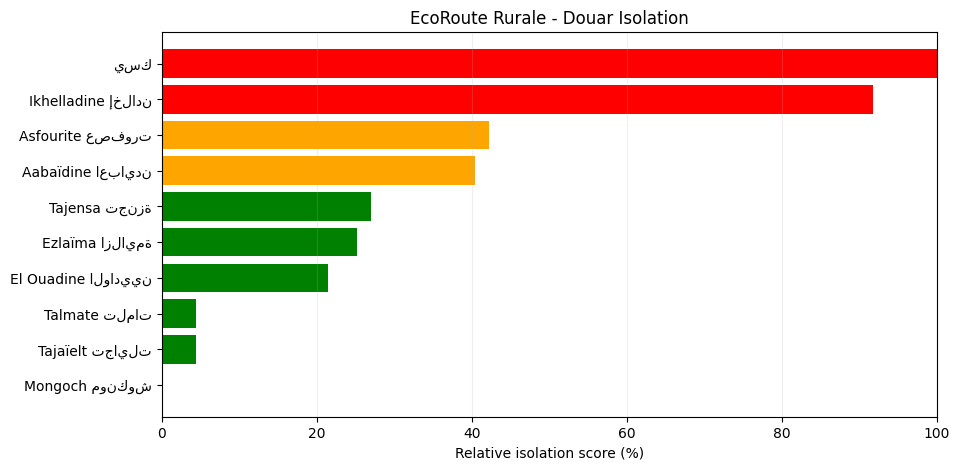

,osm_id,name,neighbor_distance_km,isolation_score,isolation_score_pct,isolation_level
8,node/13512384833,يسك,7.08,1.00,100.00,High
9,node/14140893598,Ikhelladine إخلادن,6.71,0.92,91.77,High
7,node/13592990912,Asfourite عصفورت,4.48,0.42,42.26,Medium
0,node/14140912502,Aabaïdine اعبايدن,4.39,0.40,40.44,Medium
5,node/13964798855,Tajensa تجنزة,3.79,0.27,27.03,Low
2,node/13592990910,Ezlaïma ازلايمة,3.71,0.25,25.24,Low
6,node/13592990911,El Ouadine الواديين,3.54,0.21,21.39,Low
3,node/14140912223,Talmate تلمات,2.77,0.04,4.48,Low
1,node/14140893592,Tajaïelt تجايلت,2.77,0.04,4.43,Low
4,node/13605620202,Mongoch مونكوش,2.57,0.00,0.00,Low


In [20]:
import matplotlib.pyplot as plt

def classify_isolation(score):

    if score >= 0.7:
        return "High"

    elif score >= 0.3:
        return "Medium"

    else:
        return "Low"


isolation["isolation_level"] = (
    isolation["isolation_score"].apply(classify_isolation)
)

colors = isolation["isolation_level"].map({
    "High": "red",
    "Medium": "orange",
    "Low": "green"
})

plt.figure(figsize=(10, 5))

plt.barh(
    isolation["name"],
    isolation["isolation_score_pct"],
    color=colors
)

plt.xlabel("Relative isolation score (%)")
plt.title("EcoRoute Rurale - Douar Isolation")
plt.gca().invert_yaxis()
plt.xlim(0, 100)
plt.grid(axis="x", alpha=0.2)
plt.show()

isolation.to_csv(
    OUT / "isolation_scores.csv",
    index=False
)

display(isolation.round(2))

In [21]:
# Reproducible simulated agricultural data
rng = np.random.default_rng(42)

farmers = selected[["osm_id", "name"]].copy()

# Simulated harvest quantities in kg
farmers["quantity_kg"] = rng.integers(
    200, 1201, size=len(farmers)
)

# Add isolation scores
farmers = farmers.merge(
    isolation[["osm_id", "isolation_score"]],
    on="osm_id"
)

# Add collection point information
farmers = farmers.merge(
    results[[
        "osm_id",
        "collection_id",
        "collection_point",
        "distance_km",
        "cluster"
    ]],
    on="osm_id"
)

display(farmers.round(2))

print("Total harvest:",
      farmers["quantity_kg"].sum(), "kg")

,osm_id,name,quantity_kg,isolation_score,collection_id,collection_point,distance_km,cluster
0,node/14140912502,Aabaïdine اعبايدن,289,0.40,node/13605620202,Mongoch مونكوش,2.74,2
1,node/14140893592,Tajaïelt تجايلت,974,0.04,node/13605620202,Mongoch مونكوش,2.32,2
2,node/13592990910,Ezlaïma ازلايمة,855,0.25,node/13592990910,Ezlaïma ازلايمة,0.00,1
3,node/14140912223,Talmate تلمات,639,0.04,node/13605620202,Mongoch مونكوش,2.66,2
4,node/13605620202,Mongoch مونكوش,633,0.00,node/13605620202,Mongoch مونكوش,0.00,2
5,node/13964798855,Tajensa تجنزة,1059,0.27,node/13592990910,Ezlaïma ازلايمة,1.63,1
6,node/13592990911,El Ouadine الواديين,286,0.21,node/13592990911,El Ouadine الواديين,0.00,3
7,node/13592990912,Asfourite عصفورت,898,0.42,node/13592990912,Asfourite عصفورت,0.00,4
8,node/13512384833,يسك,401,1.00,node/13512384833,يسك,0.00,5
9,node/14140893598,Ikhelladine إخلادن,294,0.92,node/14140893598,Ikhelladine إخلادن,0.00,6


Total harvest: 6328 kg


In [22]:
collection_points = farmers.groupby(
    ["collection_id", "collection_point"]
).agg(
    total_quantity_kg=("quantity_kg", "sum"),
    number_of_douars=("osm_id", "count"),
    average_isolation=("isolation_score", "mean")
).reset_index()

display(collection_points.round(2))

farmers.to_csv(
    OUT / "farmers.csv",
    index=False
)

collection_points.to_csv(
    OUT / "collection_points.csv",
    index=False
)

,collection_id,collection_point,total_quantity_kg,number_of_douars,average_isolation
0,node/13512384833,يسك,401,1,1.00
1,node/13592990910,Ezlaïma ازلايمة,1914,2,0.26
2,node/13592990911,El Ouadine الواديين,286,1,0.21
3,node/13592990912,Asfourite عصفورت,898,1,0.42
4,node/13605620202,Mongoch مونكوش,2535,4,0.12
5,node/14140893598,Ikhelladine إخلادن,294,1,0.92


In [23]:
FUEL_PRICE = 12  # MAD/L

TRUCKS = [
    {
        "id": 1,
        "capacity_kg": 4000,
        "consumption_l_100km": 18,
        "fixed_cost": 150
    },
    {
        "id": 2,
        "capacity_kg": 3000,
        "consumption_l_100km": 14,
        "fixed_cost": 120
    }
]

for truck in TRUCKS:

    truck["cost_per_km"] = (
        truck["consumption_l_100km"] * FUEL_PRICE / 100
        + truck.get("maintenance_per_km", 0)
    )

display(pd.DataFrame(TRUCKS))

print("Total fleet capacity:",
      sum(t["capacity_kg"] for t in TRUCKS), "kg")

print("Total harvest:",
      farmers["quantity_kg"].sum(), "kg")

,id,capacity_kg,consumption_l_100km,fixed_cost,cost_per_km
0,1,4000,18,150,2.16
1,2,3000,14,120,1.68


Total fleet capacity: 7000 kg
Total harvest: 6328 kg


In [24]:
from scipy.spatial import cKDTree
import geopandas as gpd
import numpy as np
from shapely.geometry import Point

# Prepare the road network spatial index
road_node_ids = list(G.nodes)

road_geometries = gpd.GeoSeries(
    [
        Point(G.nodes[n]["x"], G.nodes[n]["y"])
        for n in road_node_ids
    ],
    crs="EPSG:4326"
).to_crs(utm)

road_tree = cKDTree(
    np.column_stack([
        road_geometries.x,
        road_geometries.y
    ])
)

# General connection function
def connect_to_road_network(
    latitude,
    longitude,
    max_snap_m=500
):

    point = gpd.GeoSeries(
        [Point(longitude, latitude)],
        crs="EPSG:4326"
    ).to_crs(utm)

    distance, index = road_tree.query(
        [point.x.iloc[0], point.y.iloc[0]]
    )

    if distance > max_snap_m:
        raise ValueError(
            f"No nearby road node: {distance:.1f} m"
        )

    node = road_node_ids[index]

    return {
        "latitude": latitude,
        "longitude": longitude,
        "road_node": node,
        "snap_distance_m": float(distance),
        "road_latitude": G.nodes[node]["y"],
        "road_longitude": G.nodes[node]["x"]
    }

print("Road connection function ready.")

Road connection function ready.


In [25]:
test_location = selected.iloc[0]

connection = connect_to_road_network(
    latitude=test_location["latitude"],
    longitude=test_location["longitude"]
)

print("Location:", test_location["name"])

display(pd.DataFrame([connection]))

Location: Aabaïdine اعبايدن


,latitude,longitude,road_node,snap_distance_m,road_latitude,road_longitude
0,35.073852,-4.96684,6877661375,97.056794,35.074242,-4.965888


In [26]:
def configure_location(name, latitude, longitude):

    location = connect_to_road_network(
        latitude,
        longitude
    )

    location["name"] = name

    return location


# Departure
departure = configure_location(
    name=input("Departure name: "),
    latitude=float(input("Departure latitude: ")),
    longitude=float(input("Departure longitude: "))
)

# Destination
destination = configure_location(
    name=input("Destination name: "),
    latitude=float(input("Destination latitude: ")),
    longitude=float(input("Destination longitude: "))
)

display(pd.DataFrame([departure, destination]))

Departure name:  chefchaouane
Departure latitude:  35.1715
Departure longitude:  -5.2697
Destination name:  chefchaouane
Destination latitude:  35.1715
Destination longitude:  -5.2697


,latitude,longitude,road_node,snap_distance_m,road_latitude,road_longitude,name
0,35.1715,-5.2697,6857177237,23.953413,35.171414,-5.269941,chefchaouane
1,35.1715,-5.2697,6857177237,23.953413,35.171414,-5.269941,chefchaouane


In [27]:
locations = [
    {
        "id": "departure",
        "name": departure["name"],
        "road_node": departure["road_node"],
        "quantity_kg": 0
    }
]

selected_index = selected.set_index("osm_id")

for point in collection_points.itertuples():

    douar = selected_index.loc[point.collection_id]

    locations.append({
        "id": point.collection_id,
        "name": point.collection_point,
        "road_node": int(douar["road_node"]),
        "quantity_kg": point.total_quantity_kg
    })

locations.append({
    "id": "destination",
    "name": destination["name"],
    "road_node": destination["road_node"],
    "quantity_kg": 0
})

routing_locations = pd.DataFrame(locations)

display(routing_locations)

print("Total routing locations:", len(routing_locations))

,id,name,road_node,quantity_kg
0,departure,chefchaouane,6857177237,0
1,node/13512384833,يسك,6877878811,401
2,node/13592990910,Ezlaïma ازلايمة,6877786823,1914
3,node/13592990911,El Ouadine الواديين,6878164901,286
4,node/13592990912,Asfourite عصفورت,6878137288,898
5,node/13605620202,Mongoch مونكوش,1494307136,2535
6,node/14140893598,Ikhelladine إخلادن,6878199412,294
7,destination,chefchaouane,6857177237,0


Total routing locations: 8


In [28]:
import networkx as nx

def build_routing_matrices(G, locations):

    labels = locations["id"].tolist()
    nodes = locations["road_node"].tolist()

    n = len(labels)

    distances = np.full((n, n), np.inf)
    durations = np.full((n, n), np.inf)

    cache = {}

    for i, source in enumerate(nodes):

        print(f"Processing location {i+1}/{n}")

        if source not in cache:

            cache[source] = nx.single_source_dijkstra(
                G,
                source,
                weight="length"
            )

        lengths, paths = cache[source]

        for j, target in enumerate(nodes):

            if target not in lengths:
                continue

            distances[i, j] = lengths[target] / 1000

            path = paths[target]
            travel_seconds = 0

            for u, v in zip(path[:-1], path[1:]):

                edge = min(
                    G[u][v].values(),
                    key=lambda e: (
                        e["length"],
                        e["travel_time"]
                    )
                )

                travel_seconds += edge["travel_time"]

            durations[i, j] = travel_seconds / 60

    distance_matrix = pd.DataFrame(
        distances, index=labels, columns=labels
    )

    time_matrix = pd.DataFrame(
        durations, index=labels, columns=labels
    )

    return distance_matrix, time_matrix

In [29]:
import heapq
import numpy as np
import pandas as pd

def targeted_dijkstra(G, source, targets):

    remaining = set(targets)
    best = {source: (0.0, 0.0)}
    found = {}

    queue = [(0.0, 0.0, source)]

    while queue and remaining:

        distance, duration, u = heapq.heappop(queue)

        if (distance, duration) != best[u]:
            continue

        if u in remaining:
            found[u] = (distance, duration)
            remaining.remove(u)

        if not remaining:
            break

        for v, edges in G[u].items():

            for edge in edges.values():

                new_distance = distance + edge["length"]
                new_duration = duration + edge["travel_time"]

                candidate = (new_distance, new_duration)

                if candidate < best.get(v, (np.inf, np.inf)):

                    best[v] = candidate

                    heapq.heappush(
                        queue,
                        (new_distance, new_duration, v)
                    )

    return found


def build_routing_matrices(G, locations):

    labels = locations["id"].tolist()
    nodes = locations["road_node"].tolist()

    n = len(nodes)

    distances = np.full((n, n), np.inf)
    durations = np.full((n, n), np.inf)

    cache = {}

    for i, source in enumerate(nodes):

        print(f"Processing location {i+1}/{n}")

        if source not in cache:
            cache[source] = targeted_dijkstra(
                G, source, nodes
            )

        for j, target in enumerate(nodes):

            if target in cache[source]:

                d, t = cache[source][target]

                distances[i, j] = d / 1000
                durations[i, j] = t / 60

    return (
        pd.DataFrame(
            distances, index=labels, columns=labels
        ),
        pd.DataFrame(
            durations, index=labels, columns=labels
        )
    )


print("Memory-efficient routing function ready.")

Memory-efficient routing function ready.


In [38]:
import networkx as nx
import pandas as pd
import numpy as np
import geopandas as gpd
from pathlib import Path

OUT = Path("/content/ecoroute_data")

# Restore the saved road graph
G = nx.read_graphml(
    OUT / "roads.graphml",
    node_type=int,
    force_multigraph=True
)

# Restore numerical attribute types
for node, data in G.nodes(data=True):
    data["x"] = float(data["x"])
    data["y"] = float(data["y"])

for u, v, key, data in G.edges(keys=True, data=True):
    data["length"] = float(data["length"])
    data["travel_time"] = float(data["travel_time"])

print("Road network restored!")
print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Directed:", G.is_directed())

FileNotFoundError: [Errno 2] No such file or directory: '\\content\\ecoroute_data\\roads.graphml'

In [ ]:
from itertools import combinations

# Geographical data
douars = gpd.read_file(OUT / "douars.geojson")
boundary = gpd.read_file(OUT / "boundary.geojson")

utm = boundary.estimate_utm_crs()

# Selected douars
selected = pd.read_csv(
    OUT / "selected_with_road_nodes.csv"
)

# Distance matrices
D = pd.read_csv(
    OUT / "distance_km.csv",
    index_col=0
)

minutes = pd.read_csv(
    OUT / "travel_minutes.csv",
    index_col=0
)

ids = selected["osm_id"].tolist()
D = D.loc[ids, ids]

names = selected.set_index("osm_id")["name"]

# Previous algorithm results
results = pd.read_csv(
    OUT / "clustering_results.csv"
)

isolation = pd.read_csv(
    OUT / "isolation_scores.csv"
)

farmers = pd.read_csv(
    OUT / "farmers.csv"
)

collection_points = pd.read_csv(
    OUT / "collection_points.csv"
)

# Restore parameters
MAX_DISTANCE_KM = 3.0
K = 3

print("Data successfully restored!")
print("Available douars:", len(douars))
print("Selected douars:", len(selected))
print("Collection points:", len(collection_points))
print("Total harvest:", farmers["quantity_kg"].sum(), "kg")

In [ ]:
from scipy.spatial import cKDTree
import geopandas as gpd
import numpy as np
from shapely.geometry import Point

road_node_ids = list(G.nodes)

road_geometries = gpd.GeoSeries(
    [
        Point(G.nodes[n]["x"], G.nodes[n]["y"])
        for n in road_node_ids
    ],
    crs="EPSG:4326"
).to_crs(utm)

road_tree = cKDTree(
    np.column_stack([
        road_geometries.x,
        road_geometries.y
    ])
)

def connect_to_road_network(
    latitude,
    longitude,
    max_snap_m=500
):

    point = gpd.GeoSeries(
        [Point(longitude, latitude)],
        crs="EPSG:4326"
    ).to_crs(utm)

    distance, index = road_tree.query(
        [point.x.iloc[0], point.y.iloc[0]]
    )

    if distance > max_snap_m:
        raise ValueError(
            f"No nearby road node: {distance:.1f} m"
        )

    node = road_node_ids[index]

    return {
        "latitude": latitude,
        "longitude": longitude,
        "road_node": node,
        "snap_distance_m": float(distance),
        "road_latitude": G.nodes[node]["y"],
        "road_longitude": G.nodes[node]["x"]
    }

# Release unnecessary geometries to save RAM
del road_geometries

print("Road connection function ready.")

In [31]:
def configure_location(name, latitude, longitude):

    location = connect_to_road_network(
        latitude, longitude
    )

    location["name"] = name

    return location


departure = configure_location(
    "Chefchaouen", 35.1715, -5.2697
)

destination = configure_location(
    "Chefchaouen", 35.1715, -5.2697
)

display(pd.DataFrame([departure, destination]))

,latitude,longitude,road_node,snap_distance_m,road_latitude,road_longitude,name
0,35.1715,-5.2697,6857177237,23.953413,35.171414,-5.269941,Chefchaouen
1,35.1715,-5.2697,6857177237,23.953413,35.171414,-5.269941,Chefchaouen


In [32]:
locations = [{
    "id": "departure",
    "name": departure["name"],
    "road_node": departure["road_node"],
    "quantity_kg": 0
}]

selected_index = selected.set_index("osm_id")

for point in collection_points.itertuples():

    douar = selected_index.loc[point.collection_id]

    locations.append({
        "id": point.collection_id,
        "name": point.collection_point,
        "road_node": int(douar["road_node"]),
        "quantity_kg": point.total_quantity_kg
    })

locations.append({
    "id": "destination",
    "name": destination["name"],
    "road_node": destination["road_node"],
    "quantity_kg": 0
})

routing_locations = pd.DataFrame(locations)

display(routing_locations)

,id,name,road_node,quantity_kg
0,departure,Chefchaouen,6857177237,0
1,node/13512384833,يسك,6877878811,401
2,node/13592990910,Ezlaïma ازلايمة,6877786823,1914
3,node/13592990911,El Ouadine الواديين,6878164901,286
4,node/13592990912,Asfourite عصفورت,6878137288,898
5,node/13605620202,Mongoch مونكوش,1494307136,2535
6,node/14140893598,Ikhelladine إخلادن,6878199412,294
7,destination,Chefchaouen,6857177237,0


In [33]:
route_D, route_T = build_routing_matrices(
    G, routing_locations
)

routing_names = routing_locations.set_index("id")["name"]

print("DISTANCE MATRIX (km)")

display(
    route_D.rename(
        index=routing_names,
        columns=routing_names
    ).round(2)
)

print("TRAVEL TIME MATRIX (minutes)")

display(
    route_T.rename(
        index=routing_names,
        columns=routing_names
    ).round(2)
)

print("Matrix shape:", route_D.shape)
print("Unreachable pairs:", np.isinf(route_D.values).sum())

# Save results
route_D.to_csv(OUT / "routing_distance_km.csv")
route_T.to_csv(OUT / "routing_time_minutes.csv")
routing_locations.to_csv(
    OUT / "routing_locations.csv",
    index=False
)

print("Routing matrices saved successfully!")

Processing location 1/8
Processing location 2/8
Processing location 3/8
Processing location 4/8
Processing location 5/8
Processing location 6/8
Processing location 7/8
Processing location 8/8
DISTANCE MATRIX (km)


,Chefchaouen,يسك,Ezlaïma ازلايمة,El Ouadine الواديين,Asfourite عصفورت,Mongoch مونكوش,Ikhelladine إخلادن,Chefchaouen
Chefchaouen,0.00,47.62,57.26,50.73,49.58,51.36,52.93,0.00
يسك,47.17,0.00,12.80,7.75,6.59,6.90,9.94,47.17
Ezlaïma ازلايمة,56.81,12.80,0.00,7.49,10.49,5.90,13.84,56.81
El Ouadine الواديين,50.28,7.75,7.49,0.00,3.93,3.45,7.28,50.28
Asfourite عصفورت,49.13,6.59,10.49,3.93,0.00,4.84,4.66,49.13
Mongoch مونكوش,50.91,6.90,5.90,3.45,4.84,0.00,8.19,50.91
Ikhelladine إخلادن,52.48,9.94,13.84,7.28,4.66,8.19,0.00,52.48
Chefchaouen,0.00,47.62,57.26,50.73,49.58,51.36,52.93,0.00


TRAVEL TIME MATRIX (minutes)


,Chefchaouen,يسك,Ezlaïma ازلايمة,El Ouadine الواديين,Asfourite عصفورت,Mongoch مونكوش,Ikhelladine إخلادن,Chefchaouen
Chefchaouen,0.00,109.09,117.45,109.19,104.38,103.09,116.28,0.00
يسك,107.47,0.00,31.23,31.44,26.63,16.87,38.53,107.47
Ezlaïma ازلايمة,115.82,31.23,0.00,25.10,40.08,14.35,51.98,115.82
El Ouadine الواديين,107.56,31.44,25.10,0.00,19.66,14.46,31.55,107.56
Asfourite عصفورت,102.76,26.63,40.08,19.66,0.00,14.98,18.42,102.76
Mongoch مونكوش,101.47,16.87,14.35,14.46,14.98,0.00,26.87,101.47
Ikhelladine إخلادن,114.65,38.53,51.98,31.55,18.42,26.87,0.00,114.65
Chefchaouen,0.00,109.09,117.45,109.19,104.38,103.09,116.28,0.00


Matrix shape: (8, 8)
Unreachable pairs: 0


OSError: Cannot save file into a non-existent directory: '\content\ecoroute_data'

In [34]:
from collections import Counter
from itertools import islice

# Inspect road attributes
sample_edges = list(
    islice(G.edges(data=True), 5)
)

for u, v, data in sample_edges:
    print(data)

# Count road classifications
road_types = Counter(
    str(data.get("highway", "missing"))
    for _, _, data in G.edges(data=True)
)

print("\nROAD CLASSIFICATIONS:")

for road_type, count in road_types.most_common():
    print(road_type, ":", count)

{'length': 29.830007072753375, 'travel_time': 4.295521018476486, 'highway': 'residential', 'osmid': 34015770}
{'length': 124.15397927418437, 'travel_time': 17.87817301548255, 'highway': 'residential', 'osmid': 735250307}
{'length': 48.905704976006525, 'travel_time': 7.042421516544939, 'highway': 'residential', 'osmid': 1487970505}
{'length': 29.830007072753375, 'travel_time': 4.295521018476486, 'highway': 'residential', 'osmid': 34015770}
{'length': 31.327968052032794, 'travel_time': 4.511227399492722, 'highway': 'residential', 'osmid': 34015770}

ROAD CLASSIFICATIONS:
track : 720320
unclassified : 263966
tertiary : 38987
residential : 28045
primary : 21335
secondary : 19243
service : 11502
trunk : 222
living_street : 182
primary_link : 19
tertiary_link : 5
secondary_link : 2
trunk_link : 2


In [35]:
import heapq

MAJOR_ROADS = {
    "trunk",
    "primary",
    "secondary",
    "tertiary",
    "trunk_link",
    "primary_link",
    "secondary_link",
    "tertiary_link"
}

# Identify nodes belonging to major roads
major_road_nodes = set()

for u, v, data in G.edges(data=True):

    if data.get("highway") in MAJOR_ROADS:

        major_road_nodes.add(u)
        major_road_nodes.add(v)

print("Major road nodes:", len(major_road_nodes))


def distance_to_major_roads(G, sources, targets):

    # Reverse graph without creating a full copy
    reverse_G = G.reverse(copy=False)

    remaining = set(targets)

    best = {node: 0.0 for node in sources}

    queue = [(0.0, node) for node in sources]

    heapq.heapify(queue)

    found = {}

    while queue and remaining:

        distance, u = heapq.heappop(queue)

        if distance != best[u]:
            continue

        if u in remaining:

            found[u] = distance / 1000
            remaining.remove(u)

        if not remaining:
            break

        for v, edges in reverse_G[u].items():

            length = min(
                edge["length"]
                for edge in edges.values()
            )

            new_distance = distance + length

            if new_distance < best.get(v, float("inf")):

                best[v] = new_distance

                heapq.heappush(
                    queue,
                    (new_distance, v)
                )

    return found


# Calculate distances for the 10 selected douars
major_road_distances = distance_to_major_roads(
    G,
    major_road_nodes,
    selected["road_node"].tolist()
)

road_access = selected[
    ["osm_id", "name", "road_node"]
].copy()

road_access["distance_to_major_road_km"] = (
    road_access["road_node"].map(major_road_distances)
)

display(
    road_access.sort_values(
        "distance_to_major_road_km",
        ascending=False
    )
)

print(
    "Unreachable douars:",
    road_access["distance_to_major_road_km"].isna().sum()
)

road_access.to_csv(
    OUT / "road_access.csv",
    index=False
)

Major road nodes: 40686


,osm_id,name,road_node,distance_to_major_road_km
2,node/13592990910,Ezlaïma ازلايمة,6877786823,11.680737
5,node/13964798855,Tajensa تجنزة,6857361101,11.375849
1,node/14140893592,Tajaïelt تجايلت,1494306888,8.092549
3,node/14140912223,Talmate تلمات,6877639051,7.436905
0,node/14140912502,Aabaïdine اعبايدن,6877661375,7.210562
4,node/13605620202,Mongoch مونكوش,1494307136,6.032114
6,node/13592990911,El Ouadine الواديين,6878164901,5.120546
8,node/13512384833,يسك,6877878811,4.252164
7,node/13592990912,Asfourite عصفورت,6878137288,2.495019
9,node/14140893598,Ikhelladine إخلادن,6878199412,0.772760


Unreachable douars: 0


OSError: Cannot save file into a non-existent directory: '\content\ecoroute_data'

In [37]:
# Reverse graph without copying it
reverse_G = G.reverse(copy=False)

# Road nodes of the 10 selected douars
douar_nodes = selected["road_node"].tolist()

# Calculate routes from douars to destination
market_routes = targeted_dijkstra(
    reverse_G,
    destination["road_node"],
    douar_nodes
)

market_access = selected[
    ["osm_id", "name", "road_node"]
].copy()

# Extract distance in kilometers
market_access["distance_to_market_km"] = (
    market_access["road_node"].map(
        lambda node: market_routes.get(
            node, (np.inf, np.inf)
        )[0] / 1000
    )
)

# Extract travel time in minutes
market_access["time_to_market_min"] = (
    market_access["road_node"].map(
        lambda node: market_routes.get(
            node, (np.inf, np.inf)
        )[1] / 60
    )
)

display(
    market_access.sort_values(
        "time_to_market_min",
        ascending=False
    ).round(2)
)

print(
    "Unreachable douars:",
    np.isinf(market_access["time_to_market_min"]).sum()
)

market_access.to_csv(
    OUT / "market_access.csv",
    index=False
)

,osm_id,name,road_node,distance_to_market_km,time_to_market_min
3,node/14140912223,Talmate تلمات,6877639051,52.60,119.15
5,node/13964798855,Tajensa تجنزة,6857361101,56.93,117.36
2,node/13592990910,Ezlaïma ازلايمة,6877786823,56.81,115.82
9,node/14140893598,Ikhelladine إخلادن,6878199412,52.48,114.65
0,node/14140912502,Aabaïdine اعبايدن,6877661375,52.04,107.69
6,node/13592990911,El Ouadine الواديين,6878164901,50.28,107.56
8,node/13512384833,يسك,6877878811,47.17,107.47
1,node/14140893592,Tajaïelt تجايلت,1494306888,53.22,106.81
7,node/13592990912,Asfourite عصفورت,6878137288,49.13,102.76
4,node/13605620202,Mongoch مونكوش,1494307136,50.91,101.47


Unreachable douars: 0


OSError: Cannot save file into a non-existent directory: '\content\ecoroute_data'

In [36]:
# Preserve the preliminary isolation score
final_isolation = isolation[
    ["osm_id", "isolation_score"]
].copy()

final_isolation = final_isolation.rename(
    columns={"isolation_score": "neighbor_score"}
)

# Add road accessibility
final_isolation = final_isolation.merge(
    road_access[
        ["osm_id", "distance_to_major_road_km"]
    ],
    on="osm_id",
    validate="one_to_one"
)

# Add market accessibility
final_isolation = final_isolation.merge(
    market_access[
        ["osm_id", "name", "time_to_market_min"]
    ],
    on="osm_id",
    validate="one_to_one"
)

# Min-Max normalization
def normalize(series):

    if series.max() == series.min():
        return series * 0

    return (
        (series - series.min()) /
        (series.max() - series.min())
    )

final_isolation["road_score"] = normalize(
    final_isolation["distance_to_major_road_km"]
)

final_isolation["market_score"] = normalize(
    final_isolation["time_to_market_min"]
)

# Configurable weights
W_NEIGHBORS = 0.30
W_ROADS = 0.30
W_MARKET = 0.40

# Calculate final isolation score
final_isolation["isolation_score"] = (
    W_NEIGHBORS * final_isolation["neighbor_score"]
    + W_ROADS * final_isolation["road_score"]
    + W_MARKET * final_isolation["market_score"]
)

final_isolation["isolation_percentage"] = (
    final_isolation["isolation_score"] * 100
)

# Isolation categories
def classify_isolation(score):

    if score >= 0.7:
        return "High"

    elif score >= 0.3:
        return "Medium"

    else:
        return "Low"

final_isolation["isolation_level"] = (
    final_isolation["isolation_score"]
    .apply(classify_isolation)
)

# Sort from most to least isolated
final_isolation = final_isolation.sort_values(
    "isolation_score",
    ascending=False
)

display(final_isolation.round(3))

# Save final results
final_isolation.to_csv(
    OUT / "final_isolation_scores.csv",
    index=False
)

print("Final isolation scores saved!")

NameError: name 'market_access' is not defined

In [ ]:
# Replace preliminary isolation scores
farmers = farmers.drop(
    columns=["isolation_score"],
    errors="ignore"
)

farmers = farmers.merge(
    final_isolation[
        ["osm_id", "isolation_score", "isolation_level"]
    ],
    on="osm_id",
    how="left",
    validate="one_to_one"
)

assert farmers["isolation_score"].notna().all()

# Update collection point statistics
collection_points = farmers.groupby(
    ["collection_id", "collection_point"]
).agg(
    total_quantity_kg=("quantity_kg", "sum"),
    number_of_douars=("osm_id", "count"),
    average_isolation=("isolation_score", "mean"),
    maximum_isolation=("isolation_score", "max")
).reset_index()

print("UPDATED FARMERS")

display(farmers.round(3))

print("UPDATED COLLECTION POINTS")

display(collection_points.round(3))

# Save updated datasets
farmers.to_csv(
    OUT / "farmers.csv",
    index=False
)

collection_points.to_csv(
    OUT / "collection_points.csv",
    index=False
)

print("Total harvest:", farmers["quantity_kg"].sum(), "kg")
print("Data updated successfully!")

In [ ]:
# Configurable fleet
FUEL_PRICE = 12

TRUCKS = [
    {
        "id": 1,
        "capacity_kg": 4000,
        "consumption_l_100km": 18,
        "fixed_cost": 150
    },
    {
        "id": 2,
        "capacity_kg": 3000,
        "consumption_l_100km": 14,
        "fixed_cost": 120
    }
]

# Calculate variable cost per kilometer
for truck in TRUCKS:

    truck["cost_per_km"] = (
        truck["consumption_l_100km"]
        * FUEL_PRICE / 100
        + truck.get("maintenance_per_km", 0)
    )

# Collection point IDs
point_ids = collection_points[
    "collection_id"
].tolist()

# Demand at each collection point
demands = collection_points.set_index(
    "collection_id"
)["total_quantity_kg"].to_dict()

# Total demand and fleet capacity
total_demand = sum(demands.values())

total_capacity = sum(
    truck["capacity_kg"]
    for truck in TRUCKS
)

max_capacity = max(
    truck["capacity_kg"]
    for truck in TRUCKS
)

# Validate routing matrix
required_locations = [
    "departure",
    *point_ids,
    "destination"
]

assert set(required_locations).issubset(route_D.index)
assert set(required_locations).issubset(route_D.columns)

assert np.isfinite(
    route_D.loc[
        required_locations,
        required_locations
    ].values
).all()

print("FLEET CONFIGURATION")
display(pd.DataFrame(TRUCKS))

print("\nFEASIBILITY CHECK")

print("Collection points:", len(point_ids))
print("Available trucks:", len(TRUCKS))
print("Total demand:", total_demand, "kg")
print("Total capacity:", total_capacity, "kg")

print(
    "Remaining capacity:",
    total_capacity - total_demand,
    "kg"
)

print(
    "Fleet utilization:",
    round(total_demand / total_capacity * 100, 2),
    "%"
)

if total_demand > total_capacity:

    print("INFEASIBLE: Insufficient fleet capacity.")

elif max(demands.values()) > max_capacity:

    print("INFEASIBLE: Collection point too large.")

else:

    print("Preliminary feasibility checks passed.")

In [ ]:
from itertools import permutations

def find_best_route(assigned_points, route_D, route_T):

    # Case of an unused truck
    if len(assigned_points) == 0:

        return {
            "route": [],
            "distance_km": 0.0,
            "travel_time_min": 0.0
        }

    best_route = None
    best_distance = float("inf")
    best_time = float("inf")

    # Test all possible visiting orders
    for order in permutations(assigned_points):

        route = [
            "departure",
            *order,
            "destination"
        ]

        distance = sum(
            route_D.loc[route[i], route[i + 1]]
            for i in range(len(route) - 1)
        )

        duration = sum(
            route_T.loc[route[i], route[i + 1]]
            for i in range(len(route) - 1)
        )

        # Minimize distance, then time in case of equality
        if (distance, duration) < (best_distance, best_time):

            best_distance = distance
            best_time = duration
            best_route = route

    return {
        "route": best_route,
        "distance_km": best_distance,
        "travel_time_min": best_time
    }


print("Optimal route sequencing function ready!")

In [ ]:
test_points = point_ids[:3]

test_result = find_best_route(
    test_points,
    route_D,
    route_T
)

test_load = sum(
    demands[p] for p in test_points
)

print("ASSIGNED COLLECTION POINTS")

for p in test_points:
    print(routing_names.loc[p])

print("\nOPTIMAL ROUTE")

print(
    " → ".join(
        routing_names.loc[p]
        for p in test_result["route"]
    )
)

print(
    "\nTotal distance:",
    round(test_result["distance_km"], 2),
    "km"
)

print(
    "Travel time:",
    round(test_result["travel_time_min"], 2),
    "minutes"
)

print("Total load:", test_load, "kg")

In [ ]:
from itertools import product

def optimize_fleet(
    trucks,
    point_ids,
    demands,
    route_D,
    route_T
):

    best_solution = None
    best_cost = float("inf")

    feasible_count = 0
    tested_count = 0

    # Avoid recalculating identical routes
    route_cache = {}

    # Generate all possible assignments
    for assignment in product(
        range(len(trucks)),
        repeat=len(point_ids)
    ):

        tested_count += 1

        groups = [
            [] for _ in trucks
        ]

        # Assign collection points to trucks
        for point, truck_index in zip(
            point_ids, assignment
        ):

            groups[truck_index].append(point)

        # Calculate truck loads
        loads = [
            sum(demands[p] for p in group)
            for group in groups
        ]

        # Reject assignments exceeding capacity
        if any(
            load > truck["capacity_kg"]
            for load, truck in zip(loads, trucks)
        ):
            continue

        feasible_count += 1

        solution = []
        total_cost = 0

        for truck, group, load in zip(
            trucks, groups, loads
        ):

            # Ignore unused trucks
            if not group:
                continue

            # Reuse previously optimized routes
            key = tuple(sorted(group))

            if key not in route_cache:

                route_cache[key] = find_best_route(
                    group,
                    route_D,
                    route_T
                )

            route_result = route_cache[key]

            distance = route_result["distance_km"]

            # Transportation cost
            cost = (
                truck.get("fixed_cost", 0)
                + distance * truck["cost_per_km"]
            )

            total_cost += cost

            solution.append({
                "truck_id": truck["id"],
                "capacity_kg": truck["capacity_kg"],
                "load_kg": load,
                "collection_points": group,
                "route": route_result["route"],
                "distance_km": distance,
                "travel_time_min":
                    route_result["travel_time_min"],
                "total_cost_mad": cost
            })

        # Retain the least expensive solution
        if total_cost < best_cost:

            best_cost = total_cost
            best_solution = solution

    return {
        "solution": best_solution,
        "total_cost_mad": best_cost,
        "tested_assignments": tested_count,
        "feasible_assignments": feasible_count
    }


print("Fleet optimization function ready!")

In [ ]:
optimization = optimize_fleet(
    TRUCKS,
    point_ids,
    demands,
    route_D,
    route_T
)

if optimization["solution"] is None:

    print("No feasible solution found.")

else:

    optimal_routes = pd.DataFrame(
        optimization["solution"]
    )

    # Calculate capacity utilization
    optimal_routes["utilization_pct"] = (
        optimal_routes["load_kg"]
        / optimal_routes["capacity_kg"] * 100
    )

    # Display readable route names
    optimal_routes["route_names"] = (
        optimal_routes["route"].apply(
            lambda route: " → ".join(
                routing_names.loc[p] for p in route
            )
        )
    )

    print("OPTIMIZATION RESULTS")

    print(
        "Tested assignments:",
        optimization["tested_assignments"]
    )

    print(
        "Feasible assignments:",
        optimization["feasible_assignments"]
    )

    display(
        optimal_routes[[
            "truck_id",
            "capacity_kg",
            "load_kg",
            "utilization_pct",
            "distance_km",
            "travel_time_min",
            "total_cost_mad"
        ]].round(2)
    )

    # Display individual routes
    for row in optimal_routes.itertuples():

        print(f"\nTRUCK {row.truck_id}")
        print(row.route_names)

    print("\nGLOBAL RESULTS")

    print(
        "Total distance:",
        round(optimal_routes["distance_km"].sum(), 2),
        "km"
    )

    print(
        "Total driving time:",
        round(optimal_routes["travel_time_min"].sum(), 2),
        "minutes"
    )

    print(
        "Total transported quantity:",
        optimal_routes["load_kg"].sum(),
        "kg"
    )

    print(
        "Minimum transportation cost:",
        round(optimization["total_cost_mad"], 2),
        "MAD"
    )

    # Save results
    optimal_routes.to_csv(
        OUT / "optimal_routes.csv",
        index=False
    )

In [ ]:
truck_config = pd.DataFrame(TRUCKS).set_index("id")

# Fuel consumption rate
optimal_routes["consumption_l_100km"] = (
    optimal_routes["truck_id"].map(
        truck_config["consumption_l_100km"]
    )
)

# Total fuel consumption
optimal_routes["fuel_consumption_l"] = (
    optimal_routes["distance_km"]
    * optimal_routes["consumption_l_100km"]
    / 100
)

# Fuel cost
optimal_routes["fuel_cost_mad"] = (
    optimal_routes["fuel_consumption_l"]
    * FUEL_PRICE
)

# Fixed costs
optimal_routes["fixed_cost_mad"] = (
    optimal_routes["truck_id"].map({
        truck["id"]: truck.get("fixed_cost", 0)
        for truck in TRUCKS
    })
)

# Optional maintenance costs
optimal_routes["maintenance_cost_mad"] = (
    optimal_routes["distance_km"]
    * optimal_routes["truck_id"].map({
        truck["id"]: truck.get("maintenance_per_km", 0)
        for truck in TRUCKS
    })
)

# Average transportation cost per kg
optimal_routes["cost_per_kg"] = (
    optimal_routes["total_cost_mad"]
    / optimal_routes["load_kg"]
)

# Estimated CO2 emissions
CO2_PER_LITER = 2.68

optimal_routes["co2_kg"] = (
    optimal_routes["fuel_consumption_l"]
    * CO2_PER_LITER
)

print("DETAILED COST BREAKDOWN")

display(optimal_routes[[
    "truck_id",
    "fuel_consumption_l",
    "fuel_cost_mad",
    "fixed_cost_mad",
    "maintenance_cost_mad",
    "total_cost_mad",
    "cost_per_kg",
    "co2_kg"
]].round(3))

# Global indicators
total_fuel = optimal_routes["fuel_consumption_l"].sum()
total_cost = optimal_routes["total_cost_mad"].sum()
total_co2 = optimal_routes["co2_kg"].sum()
total_load = optimal_routes["load_kg"].sum()

print("\nGLOBAL INDICATORS")

print("Total fuel:", round(total_fuel, 2), "L")
print("Total cost:", round(total_cost, 2), "MAD")
print("Average cost per kg:", round(total_cost / total_load, 4), "MAD/kg")
print("Estimated CO2 emissions:", round(total_co2, 2), "kg")

print(
    "Parallel driving duration:",
    round(optimal_routes["travel_time_min"].max(), 2),
    "minutes"
)

optimal_routes.to_csv(
    OUT / "optimal_routes.csv",
    index=False
)

In [ ]:
from collections import Counter

def validate_solution(
    optimal_routes,
    point_ids,
    demands,
    trucks,
    route_D
):

    checks = {}

    # 1. Verify collection point coverage
    visited_points = [
        point
        for route in optimal_routes["route"]
        for point in route[1:-1]
    ]

    checks["All collection points served exactly once"] = (
        Counter(visited_points) == Counter(point_ids)
    )

    # 2. Verify truck capacities
    capacities = {
        truck["id"]: truck["capacity_kg"]
        for truck in trucks
    }

    checks["Truck capacities respected"] = all(
        row.load_kg <= capacities[row.truck_id]
        for row in optimal_routes.itertuples()
    )

    # 3. Verify individual truck loads
    checks["Individual truck loads consistent"] = all(
        row.load_kg == sum(
            demands[p] for p in row.route[1:-1]
        )
        for row in optimal_routes.itertuples()
    )

    # 4. Verify total transported quantity
    checks["Entire harvest transported"] = (
        optimal_routes["load_kg"].sum()
        == sum(demands.values())
    )

    # 5. Verify departure and destination
    checks["Departure and destination respected"] = all(
        route[0] == "departure"
        and route[-1] == "destination"
        for route in optimal_routes["route"]
    )

    # 6. Verify route distances
    checks["Route distances consistent"] = all(
        np.isclose(
            row.distance_km,
            sum(
                route_D.loc[
                    row.route[i],
                    row.route[i + 1]
                ]
                for i in range(len(row.route) - 1)
            )
        )
        for row in optimal_routes.itertuples()
    )

    # 7. Verify transportation costs
    checks["Transportation costs consistent"] = (
        np.allclose(
            optimal_routes["total_cost_mad"],
            optimal_routes["fuel_cost_mad"]
            + optimal_routes["fixed_cost_mad"]
            + optimal_routes["maintenance_cost_mad"]
        )
    )

    # 8. Verify one trip per truck
    checks["Each truck used at most once"] = (
        optimal_routes["truck_id"].is_unique
    )

    return checks


validation = validate_solution(
    optimal_routes,
    point_ids,
    demands,
    TRUCKS,
    route_D
)

print("OPTIMAL SOLUTION VALIDATION\n")

for criterion, passed in validation.items():

    status = "PASS" if passed else "FAIL"

    print(f"[{status}] {criterion}")

print(
    "\nValidation score:",
    sum(validation.values()),
    "/",
    len(validation)
)

if all(validation.values()):
    print("Solution successfully validated!")
else:
    print("Warning: Invalid solution detected.")

In [ ]:
# Reconstruct actual road paths

location_nodes = routing_locations.set_index(
    "id"
)["road_node"].to_dict()

route_geometries = {}
route_path_cache = {}

for row in optimal_routes.itertuples():

    full_path = []
    reconstructed_distance = 0

    print(f"Reconstructing Truck {row.truck_id}...")

    for start, end in zip(
        row.route[:-1],
        row.route[1:]
    ):

        source = location_nodes[start]
        target = location_nodes[end]

        key = (source, target)

        if key not in route_path_cache:

            distance, path = nx.bidirectional_dijkstra(
                G,
                source,
                target,
                weight="length"
            )

            route_path_cache[key] = (distance, path)

        distance, path = route_path_cache[key]

        reconstructed_distance += distance

        # Avoid duplicating connecting nodes
        if full_path:
            full_path.extend(path[1:])
        else:
            full_path.extend(path)

    # Convert road nodes into geographical coordinates
    coordinates = [
        (G.nodes[node]["y"], G.nodes[node]["x"])
        for node in full_path
    ]

    route_geometries[row.truck_id] = coordinates

    reconstructed_km = reconstructed_distance / 1000

    print("Road nodes:", len(full_path))

    print(
        "Reconstructed distance:",
        round(reconstructed_km, 2),
        "km"
    )

    print(
        "Optimized distance:",
        round(row.distance_km, 2),
        "km"
    )

    assert np.isclose(
        reconstructed_km,
        row.distance_km
    ), "Distance mismatch!"

    print("Route successfully reconstructed!\n")

print("All route geometries are ready!")

In [ ]:
import folium
import geopandas as gpd

from html import escape
from shapely.geometry import LineString, box
from IPython.display import display
from branca.element import Element


# ==================================================
# 1. PREPARE GEOGRAPHICAL DATA
# ==================================================

geo_farmers = farmers.merge(
    selected[["osm_id", "latitude", "longitude"]],
    on="osm_id",
    how="left",
    validate="one_to_one"
)

geo_index = geo_farmers.set_index("osm_id")

collection_index = collection_points.set_index(
    "collection_id"
)


# ==================================================
# 2. INITIALIZE MAP WITHOUT EXTERNAL TILES
# ==================================================

route_map = folium.Map(
    location=[
        geo_farmers["latitude"].mean(),
        geo_farmers["longitude"].mean()
    ],
    zoom_start=11,
    tiles=None,
    control_scale=True
)


# ==================================================
# 3. LOCAL GEOGRAPHICAL BACKGROUND
# ==================================================

# Province boundary
folium.GeoJson(
    boundary.to_crs("EPSG:4326"),
    name="Chefchaouen province",
    style_function=lambda feature: {
        "color": "#64748b",
        "weight": 2,
        "fillColor": "#e2e8d5",
        "fillOpacity": 0.25
    }
).add_to(route_map)


# Determine the operational geographical area
coords = [
    coord
    for route in route_geometries.values()
    for coord in route
]

coords.extend(
    geo_farmers[["latitude", "longitude"]]
    .values.tolist()
)

latitudes = [p[0] for p in coords]
longitudes = [p[1] for p in coords]

margin = 0.03

area = box(
    min(longitudes) - margin,
    min(latitudes) - margin,
    max(longitudes) + margin,
    max(latitudes) + margin
)


# Select main road categories
major_types = {
    "trunk",
    "primary",
    "secondary",
    "tertiary",
    "trunk_link",
    "primary_link",
    "secondary_link",
    "tertiary_link"
}

road_lines = []
seen_edges = set()

print("Preparing local road network...")

for u, v, data in G.edges(data=True):

    if data.get("highway") not in major_types:
        continue

    # Avoid duplicate road segments
    edge_key = tuple(sorted((u, v)))

    if edge_key in seen_edges:
        continue

    seen_edges.add(edge_key)

    line = LineString([
        (G.nodes[u]["x"], G.nodes[u]["y"]),
        (G.nodes[v]["x"], G.nodes[v]["y"])
    ])

    if line.intersects(area):
        road_lines.append(line)


# Create geographical road layer
local_roads = gpd.GeoDataFrame(
    geometry=road_lines,
    crs="EPSG:4326"
)

# Merge road segments into a lighter geometry
if not local_roads.empty:

    merged_roads = gpd.GeoDataFrame(
        geometry=[local_roads.geometry.unary_union],
        crs="EPSG:4326"
    )

    folium.GeoJson(
        merged_roads,
        name="Local road network",
        style_function=lambda feature: {
            "color": "#94a3b8",
            "weight": 1.5,
            "opacity": 0.7
        }
    ).add_to(route_map)

print("Local road segments:", len(local_roads))
print("Local geographical background ready!")


# ==================================================
# 4. CREATE INTERACTIVE LAYERS
# ==================================================

collection_layer = folium.FeatureGroup(
    name="Collection points"
)

douar_layer = folium.FeatureGroup(
    name="Other douars"
)

assignment_layer = folium.FeatureGroup(
    name="Douar assignments",
    show=False
)

location_layer = folium.FeatureGroup(
    name="Departure and destination"
)

colors = [
    "#2563eb",
    "#16a34a",
    "#dc2626",
    "#9333ea",
    "#0891b2"
]

point_to_truck = {}


# ==================================================
# 5. DRAW OPTIMIZED TRUCK ROUTES
# ==================================================

for i, row in enumerate(optimal_routes.itertuples()):

    color = colors[i % len(colors)]

    truck_layer = folium.FeatureGroup(
        name=f"Truck {row.truck_id} route"
    )

    popup = f"""
    <b>Truck {row.truck_id}</b><br>
    Distance: {row.distance_km:.2f} km<br>
    Load: {row.load_kg} kg<br>
    Capacity: {row.capacity_kg} kg<br>
    Utilization: {row.utilization_pct:.2f}%<br>
    Driving time: {row.travel_time_min:.2f} min<br>
    Fuel: {row.fuel_consumption_l:.2f} L<br>
    Cost: {row.total_cost_mad:.2f} MAD<br>
    CO2: {row.co2_kg:.2f} kg
    """

    folium.PolyLine(
        locations=route_geometries[row.truck_id],
        color=color,
        weight=6 if i == 0 else 4,
        opacity=0.9,
        dash_array=None if i == 0 else "10, 10",
        tooltip=f"Truck {row.truck_id}",
        popup=folium.Popup(popup, max_width=300)
    ).add_to(truck_layer)

    truck_layer.add_to(route_map)

    for point in row.route[1:-1]:
        point_to_truck[point] = row.truck_id


# ==================================================
# 6. DRAW COLLECTION POINTS
# ==================================================

for row in collection_points.itertuples():

    point = geo_index.loc[row.collection_id]

    popup = f"""
    <b>{escape(str(row.collection_point))}</b><br>
    Type: Collection point<br>
    Total harvest: {row.total_quantity_kg} kg<br>
    Assigned douars: {row.number_of_douars}<br>
    Average isolation: {row.average_isolation:.1%}<br>
    Maximum isolation: {row.maximum_isolation:.1%}<br>
    Assigned truck: {point_to_truck[row.collection_id]}
    """

    folium.Marker(
        location=[
            point["latitude"],
            point["longitude"]
        ],
        tooltip=row.collection_point,
        popup=folium.Popup(popup, max_width=300),
        icon=folium.Icon(
            color="orange",
            icon="archive",
            prefix="fa"
        )
    ).add_to(collection_layer)


# ==================================================
# 7. DRAW OTHER DOUARS
# ==================================================

for row in geo_farmers.itertuples():

    if row.osm_id == row.collection_id:
        continue

    popup = f"""
    <b>{escape(str(row.name))}</b><br>
    Harvest: {row.quantity_kg} kg<br>
    Isolation score: {row.isolation_score:.1%}<br>
    Isolation level: {row.isolation_level}<br>
    Collection point: {escape(str(row.collection_point))}<br>
    Road distance: {row.distance_km:.2f} km
    """

    folium.CircleMarker(
        location=[row.latitude, row.longitude],
        radius=7,
        color="#9333ea",
        fill=True,
        fill_color="#9333ea",
        fill_opacity=0.85,
        tooltip=row.name,
        popup=folium.Popup(popup, max_width=300)
    ).add_to(douar_layer)

    # Illustrative connection to collection point
    center = geo_index.loc[row.collection_id]

    folium.PolyLine(
        locations=[
            [row.latitude, row.longitude],
            [center["latitude"], center["longitude"]]
        ],
        color="gray",
        weight=2,
        dash_array="6, 6",
        tooltip=(
            f"Assignment: {row.distance_km:.2f} km "
            "(road distance)"
        )
    ).add_to(assignment_layer)


# ==================================================
# 8. DRAW DEPARTURE AND DESTINATION
# ==================================================

same_location = (
    departure["latitude"] == destination["latitude"]
    and
    departure["longitude"] == destination["longitude"]
)

if same_location:

    folium.Marker(
        location=[
            departure["latitude"],
            departure["longitude"]
        ],
        tooltip="Departure and destination",
        popup=escape(str(departure["name"])),
        icon=folium.Icon(
            color="red",
            icon="flag",
            prefix="fa"
        )
    ).add_to(location_layer)

else:

    for label, location, color in [
        ("Departure", departure, "red"),
        ("Destination", destination, "darkred")
    ]:

        folium.Marker(
            location=[
                location["latitude"],
                location["longitude"]
            ],
            tooltip=label,
            popup=escape(str(location["name"])),
            icon=folium.Icon(
                color=color,
                icon="flag",
                prefix="fa"
            )
        ).add_to(location_layer)


# ==================================================
# 9. ADD LAYERS AND CONTROLS
# ==================================================

collection_layer.add_to(route_map)
douar_layer.add_to(route_map)
assignment_layer.add_to(route_map)
location_layer.add_to(route_map)

folium.LayerControl(
    collapsed=False
).add_to(route_map)

folium.plugins if hasattr(folium, "plugins") else None


# ==================================================
# 10. ADD MAP LEGEND
# ==================================================

legend_html = """
<div style="
    position: fixed;
    bottom: 35px;
    left: 15px;
    z-index: 9999;
    background: white;
    padding: 14px;
    border: 1px solid #cccccc;
    border-radius: 8px;
    font-size: 12px;
    color: #333333;
    box-shadow: 0 2px 8px #00000020;
">

    <b style="font-size: 15px;">
        EcoRoute Rurale
    </b>

    <hr style="margin: 8px 0;">

    <span style="color:#2563eb;">━━━━</span>
    Truck 1<br>

    <span style="color:#16a34a;">┅┅┅┅</span>
    Truck 2<br>

    <span style="color:#ea580c;">●</span>
    Collection point<br>

    <span style="color:#9333ea;">●</span>
    Other douar<br>

    <span style="color:#dc2626;">●</span>
    Departure / Destination<br>

    <span style="color:#94a3b8;">━━━━</span>
    Main road network<br>

    <span style="color:#64748b;">□</span>
    Province boundary

</div>
"""

route_map.get_root().html.add_child(
    Element(legend_html)
)


# ==================================================
# 11. ADD DATA ATTRIBUTION
# ==================================================

attribution_html = """
<div style="
    position: fixed;
    bottom: 5px;
    right: 5px;
    z-index: 9999;
    background: white;
    padding: 4px;
    font-size: 11px;
">
    © <a href="https://www.openstreetmap.org/copyright"
         target="_blank">OpenStreetMap contributors</a>
    | Data: Geofabrik
</div>
"""

route_map.get_root().html.add_child(
    Element(attribution_html)
)


# ==================================================
# 12. ADJUST MAP BOUNDS
# ==================================================

all_coordinates = [
    coordinate
    for coordinates in route_geometries.values()
    for coordinate in coordinates
]

all_coordinates.extend(
    geo_farmers[["latitude", "longitude"]]
    .values.tolist()
)

all_coordinates.extend([
    [departure["latitude"], departure["longitude"]],
    [destination["latitude"], destination["longitude"]]
])

route_map.fit_bounds(
    all_coordinates,
    padding=(30, 30)
)


# ==================================================
# 13. SAVE AND DISPLAY MAP
# ==================================================

route_map.save(
    str(OUT / "optimized_routes_map.html")
)

print("\nInteractive map successfully created!")
print("Map saved:", OUT / "optimized_routes_map.html")

display(route_map)

In [ ]:
from shapely.geometry import LineString
import geopandas as gpd

route_features = []

for row in optimal_routes.itertuples():

    coordinates = route_geometries[row.truck_id]

    # Convert (latitude, longitude) to (longitude, latitude)
    geometry = LineString([
        (lon, lat)
        for lat, lon in coordinates
    ])

    route_features.append({
        "truck_id": row.truck_id,
        "load_kg": row.load_kg,
        "capacity_kg": row.capacity_kg,
        "distance_km": row.distance_km,
        "travel_time_min": row.travel_time_min,
        "total_cost_mad": row.total_cost_mad,
        "fuel_consumption_l": row.fuel_consumption_l,
        "co2_kg": row.co2_kg,
        "geometry": geometry
    })

routes_gdf = gpd.GeoDataFrame(
    route_features,
    geometry="geometry",
    crs="EPSG:4326"
)

# Export optimized routes
routes_gdf.to_file(
    OUT / "optimized_routes.geojson",
    driver="GeoJSON"
)

# Export local road network
local_roads.to_file(
    OUT / "local_roads.geojson",
    driver="GeoJSON"
)

# Export geographical farmer information
farmers_gdf = gpd.GeoDataFrame(
    geo_farmers.copy(),
    geometry=gpd.points_from_xy(
        geo_farmers["longitude"],
        geo_farmers["latitude"]
    ),
    crs="EPSG:4326"
)

farmers_gdf.to_file(
    OUT / "farmers.geojson",
    driver="GeoJSON"
)

print("Geographical exports completed!")

for filename in [
    "optimized_routes.geojson",
    "local_roads.geojson",
    "farmers.geojson",
    "optimized_routes_map.html"
]:

    path = OUT / filename

    print(
        filename,
        "—",
        round(path.stat().st_size / 1024, 2),
        "KB"
    )

In [ ]:
# ==================================================
# CELL 18.1 — CONVENTIONAL TRANSPORT BASELINE
# ==================================================

# Configurable conventional transport parameters
BASELINE_FIXED_COST = 50       # MAD per douar
BASELINE_COST_PER_KM = 3       # MAD/km

# Prepare pricing dataset
pricing = farmers.copy()

# Add real road distances to the market
pricing = pricing.merge(
    market_access[[
        "osm_id",
        "distance_to_market_km",
        "time_to_market_min"
    ]],
    on="osm_id",
    how="left",
    validate="one_to_one"
)

# Validate distances
assert pricing["distance_to_market_km"].notna().all()

assert np.isfinite(
    pricing["distance_to_market_km"]
).all()

# Conventional transport cost
pricing["baseline_cost_mad"] = (
    BASELINE_FIXED_COST
    + pricing["distance_to_market_km"]
    * BASELINE_COST_PER_KM
)

# Conventional cost per kilogram
pricing["baseline_cost_per_kg"] = (
    pricing["baseline_cost_mad"]
    / pricing["quantity_kg"]
)

print("CONVENTIONAL TRANSPORT BASELINE")

display(pricing[[
    "name",
    "quantity_kg",
    "distance_to_market_km",
    "isolation_score",
    "baseline_cost_mad",
    "baseline_cost_per_kg"
]].round(3))

# Global comparison
baseline_total_cost = pricing["baseline_cost_mad"].sum()

optimized_total_cost = optimal_routes[
    "total_cost_mad"
].sum()

potential_savings = (
    baseline_total_cost - optimized_total_cost
)

print("\nGLOBAL BASELINE INDICATORS")

print(
    "Conventional transport cost:",
    round(baseline_total_cost, 2),
    "MAD"
)

print(
    "Optimized transportation cost:",
    round(optimized_total_cost, 2),
    "MAD"
)

print(
    "Potential gross savings:",
    round(potential_savings, 2),
    "MAD"
)

print(
    "Potential gross savings percentage:",
    round(
        potential_savings / baseline_total_cost * 100,
        2
    ),
    "%"
)

pricing.to_csv(
    OUT / "pricing_baseline.csv",
    index=False
)

In [ ]:
# ==================================================
# CELL 18.2 — PROPORTIONAL COST ALLOCATION
# ==================================================

# Total optimized transportation cost
total_transport_cost = optimal_routes[
    "total_cost_mad"
].sum()

# Total agricultural quantity
total_quantity = pricing["quantity_kg"].sum()

assert total_quantity > 0
assert (pricing["quantity_kg"] > 0).all()
assert (pricing["baseline_cost_mad"] > 0).all()

# Uniform price per kilogram
proportional_rate = (
    total_transport_cost / total_quantity
)

# Proportional price per douar
pricing["proportional_price_mad"] = (
    pricing["quantity_kg"] * proportional_rate
)

# Individual gross savings
pricing["proportional_savings_mad"] = (
    pricing["baseline_cost_mad"]
    - pricing["proportional_price_mad"]
)

# Individual gross savings percentage
pricing["proportional_savings_pct"] = (
    pricing["proportional_savings_mad"]
    / pricing["baseline_cost_mad"] * 100
)

# Check whether each douar benefits
pricing["proportional_benefits"] = (
    pricing["proportional_savings_mad"] > 0
)

# Validate full cost recovery
assert np.isclose(
    pricing["proportional_price_mad"].sum(),
    total_transport_cost
)

print("PROPORTIONAL PRICING RESULTS")

display(pricing[[
    "name",
    "quantity_kg",
    "isolation_score",
    "baseline_cost_mad",
    "proportional_price_mad",
    "proportional_savings_mad",
    "proportional_savings_pct",
    "proportional_benefits"
]].round(3))


# ==================================================
# GLOBAL INDICATORS
# ==================================================

print("\nGLOBAL INDICATORS")

print(
    "Uniform price:",
    round(proportional_rate, 4),
    "MAD/kg"
)

print(
    "Total collected revenue:",
    round(pricing["proportional_price_mad"].sum(), 2),
    "MAD"
)

print(
    "Total gross savings:",
    round(pricing["proportional_savings_mad"].sum(), 2),
    "MAD"
)

print(
    "Benefiting douars:",
    pricing["proportional_benefits"].sum(),
    "/",
    len(pricing)
)

print(
    "Minimum savings percentage:",
    round(pricing["proportional_savings_pct"].min(), 2),
    "%"
)

print(
    "Maximum savings percentage:",
    round(pricing["proportional_savings_pct"].max(), 2),
    "%"
)

print(
    "Average individual savings percentage:",
    round(pricing["proportional_savings_pct"].mean(), 2),
    "%"
)

print("Full cost recovery: PASS")

# Save intermediate results
pricing.to_csv(
    OUT / "proportional_pricing.csv",
    index=False
)

In [ ]:
# ==================================================
# CELL 18.3 — ISOLATION-BASED FAIR PRICING
# ==================================================

# Configurable solidarity coefficient
ALPHA = 0.5

assert 0 <= ALPHA <= 1

assert pricing["isolation_score"].between(0, 1).all()

# Calculate isolation-adjusted weights
pricing["solidarity_weight"] = (
    pricing["quantity_kg"]
    * (1 - ALPHA * pricing["isolation_score"])
)

total_weight = pricing["solidarity_weight"].sum()

assert total_weight > 0

# Fair price per douar
pricing["fair_price_mad"] = (
    total_transport_cost
    * pricing["solidarity_weight"]
    / total_weight
)

# Fair price per kilogram
pricing["fair_price_per_kg"] = (
    pricing["fair_price_mad"]
    / pricing["quantity_kg"]
)

# Savings compared with conventional transport
pricing["fair_savings_mad"] = (
    pricing["baseline_cost_mad"]
    - pricing["fair_price_mad"]
)

pricing["fair_savings_pct"] = (
    pricing["fair_savings_mad"]
    / pricing["baseline_cost_mad"]
    * 100
)

# Additional benefit compared with proportional pricing
pricing["solidarity_benefit_mad"] = (
    pricing["proportional_price_mad"]
    - pricing["fair_price_mad"]
)

pricing["solidarity_benefit_pct"] = (
    pricing["solidarity_benefit_mad"]
    / pricing["proportional_price_mad"]
    * 100
)

# Check individual gross benefits
pricing["fair_benefits"] = (
    pricing["fair_savings_mad"] > 0
)

# Validate full cost recovery
assert np.isclose(
    pricing["fair_price_mad"].sum(),
    total_transport_cost
)

# Validate non-negative prices
assert (pricing["fair_price_mad"] >= 0).all()

# Validate solidarity redistribution
assert np.isclose(
    pricing["solidarity_benefit_mad"].sum(),
    0
)

print("ISOLATION-BASED FAIR PRICING")
print("Solidarity coefficient:", ALPHA)

display(
    pricing[[
        "name",
        "quantity_kg",
        "isolation_score",
        "proportional_price_mad",
        "fair_price_mad",
        "fair_price_per_kg",
        "solidarity_benefit_mad",
        "fair_savings_pct",
        "fair_benefits"
    ]]
    .sort_values(
        "isolation_score",
        ascending=False
    )
    .round(3)
)


# ==================================================
# GLOBAL INDICATORS
# ==================================================

print("\nGLOBAL INDICATORS")

print(
    "Total collected revenue:",
    round(pricing["fair_price_mad"].sum(), 2),
    "MAD"
)

print(
    "Total gross savings:",
    round(pricing["fair_savings_mad"].sum(), 2),
    "MAD"
)

print(
    "Benefiting douars:",
    pricing["fair_benefits"].sum(),
    "/",
    len(pricing)
)

print(
    "Minimum savings percentage:",
    round(pricing["fair_savings_pct"].min(), 2),
    "%"
)

print(
    "Maximum savings percentage:",
    round(pricing["fair_savings_pct"].max(), 2),
    "%"
)

print(
    "Minimum price per kg:",
    round(pricing["fair_price_per_kg"].min(), 4),
    "MAD/kg"
)

print(
    "Maximum price per kg:",
    round(pricing["fair_price_per_kg"].max(), 4),
    "MAD/kg"
)

print(
    "Douars receiving additional solidarity benefits:",
    (pricing["solidarity_benefit_mad"] > 0).sum()
)

print("Full cost recovery: PASS")
print("Solidarity redistribution: PASS")

# Save intermediate results
pricing.to_csv(
    OUT / "fair_pricing.csv",
    index=False
)

In [ ]:
# ==================================================
# CELL 18.4 — FINANCIAL FEASIBILITY
# ==================================================

# Configurable parameters
LOCAL_COST_PER_KG_KM = 0.01
MIN_SAVINGS_PCT = 20

assert LOCAL_COST_PER_KG_KM >= 0
assert 0 <= MIN_SAVINGS_PCT < 100

# Local transportation costs
pricing["local_transport_cost_mad"] = (
    pricing["quantity_kg"]
    * pricing["distance_km"]
    * LOCAL_COST_PER_KG_KM
)

# Convert columns into NumPy arrays
quantities = pricing["quantity_kg"].to_numpy()

isolation_scores = pricing[
    "isolation_score"
].to_numpy()

baseline_costs = pricing[
    "baseline_cost_mad"
].to_numpy()

local_costs = pricing[
    "local_transport_cost_mad"
].to_numpy()

# Maximum acceptable total cost per douar
maximum_acceptable_costs = (
    baseline_costs
    * (1 - MIN_SAVINGS_PCT / 100)
)


# ==================================================
# SOLIDARITY COEFFICIENT SEARCH
# ==================================================

def evaluate_alpha(alpha):

    weights = quantities * (
        1 - alpha * isolation_scores
    )

    if weights.sum() <= 0:
        return None

    prices = (
        total_transport_cost
        * weights
        / weights.sum()
    )

    effective_costs = prices + local_costs

    net_savings = (
        baseline_costs - effective_costs
    )

    net_savings_pct = (
        net_savings / baseline_costs * 100
    )

    feasible = (
        np.all(prices >= 0)
        and np.isclose(
            prices.sum(),
            total_transport_cost
        )
        and np.all(
            effective_costs
            <= maximum_acceptable_costs + 1e-8
        )
    )

    return {
        "alpha": alpha,
        "prices": prices,
        "effective_costs": effective_costs,
        "net_savings": net_savings,
        "net_savings_pct": net_savings_pct,
        "feasible": feasible
    }


# Test 1001 solidarity coefficients
alpha_candidates = np.linspace(0, 1, 1001)

feasible_solutions = []

for alpha in alpha_candidates:

    result = evaluate_alpha(alpha)

    if result is not None and result["feasible"]:

        feasible_solutions.append(result)


# ==================================================
# SELECT MAXIMUM FEASIBLE SOLIDARITY
# ==================================================

if not feasible_solutions:

    optimal_alpha = None

    print("NO FEASIBLE PRICING SOLUTION")
    print(
        "The current pricing model cannot guarantee",
        MIN_SAVINGS_PCT,
        "% savings for every douar."
    )

else:

    best_pricing = max(
        feasible_solutions,
        key=lambda result: result["alpha"]
    )

    optimal_alpha = best_pricing["alpha"]

    pricing["final_price_mad"] = (
        best_pricing["prices"]
    )

    pricing["final_price_per_kg"] = (
        pricing["final_price_mad"]
        / pricing["quantity_kg"]
    )

    pricing["effective_cost_mad"] = (
        best_pricing["effective_costs"]
    )

    pricing["net_savings_mad"] = (
        best_pricing["net_savings"]
    )

    pricing["net_savings_pct"] = (
        best_pricing["net_savings_pct"]
    )

    pricing["final_solidarity_benefit_mad"] = (
        pricing["proportional_price_mad"]
        - pricing["final_price_mad"]
    )

    print("OPTIMAL FAIR PRICING")

    print(
        "Optimal solidarity coefficient:",
        round(optimal_alpha, 3)
    )

    print(
        "Feasible coefficients:",
        len(feasible_solutions),
        "/",
        len(alpha_candidates)
    )

    display(
        pricing[[
            "name",
            "quantity_kg",
            "isolation_score",
            "baseline_cost_mad",
            "final_price_mad",
            "local_transport_cost_mad",
            "effective_cost_mad",
            "net_savings_mad",
            "net_savings_pct",
            "final_solidarity_benefit_mad"
        ]]
        .sort_values(
            "isolation_score",
            ascending=False
        )
        .round(3)
    )

    print("\nGLOBAL INDICATORS")

    print(
        "Total transporter revenue:",
        round(pricing["final_price_mad"].sum(), 2),
        "MAD"
    )

    print(
        "Total local transportation cost:",
        round(local_costs.sum(), 2),
        "MAD"
    )

    print(
        "Total effective transportation cost:",
        round(pricing["effective_cost_mad"].sum(), 2),
        "MAD"
    )

    print(
        "Total net savings:",
        round(pricing["net_savings_mad"].sum(), 2),
        "MAD"
    )

    print(
        "Global net savings percentage:",
        round(
            pricing["net_savings_mad"].sum()
            / baseline_costs.sum() * 100,
            2
        ),
        "%"
    )

    print(
        "Minimum individual net savings:",
        round(pricing["net_savings_pct"].min(), 2),
        "%"
    )

    print(
        "Maximum individual net savings:",
        round(pricing["net_savings_pct"].max(), 2),
        "%"
    )

    print(
        "Benefiting douars:",
        (pricing["net_savings_mad"] > 0).sum(),
        "/",
        len(pricing)
    )

    print("Full cost recovery: PASS")
    print("Minimum savings constraint: PASS")

    pricing.to_csv(
        OUT / "optimized_fair_pricing.csv",
        index=False
    )

In [ ]:
# ==================================================
# CELL 18.5 — SOCIAL IMPACT ANALYSIS
# ==================================================

assert optimal_alpha is not None

# Proportional pricing including local costs
pricing["proportional_effective_cost_mad"] = (
    pricing["proportional_price_mad"]
    + pricing["local_transport_cost_mad"]
)

# Net savings without solidarity
pricing["proportional_net_savings_mad"] = (
    pricing["baseline_cost_mad"]
    - pricing["proportional_effective_cost_mad"]
)

pricing["proportional_net_savings_pct"] = (
    pricing["proportional_net_savings_mad"]
    / pricing["baseline_cost_mad"]
    * 100
)

# Additional savings generated by solidarity
pricing["solidarity_gain_mad"] = (
    pricing["net_savings_mad"]
    - pricing["proportional_net_savings_mad"]
)

# Improvement in savings percentage points
pricing["solidarity_gain_pp"] = (
    pricing["net_savings_pct"]
    - pricing["proportional_net_savings_pct"]
)

# Classify solidarity beneficiaries
pricing["solidarity_role"] = np.select(
    [
        pricing["solidarity_gain_mad"] > 1e-8,
        pricing["solidarity_gain_mad"] < -1e-8
    ],
    [
        "Beneficiary",
        "Contributor"
    ],
    default="Neutral"
)

print("INDIVIDUAL SOCIAL IMPACT")

display(
    pricing[[
        "name",
        "isolation_level",
        "isolation_score",
        "proportional_net_savings_pct",
        "net_savings_pct",
        "solidarity_gain_mad",
        "solidarity_gain_pp",
        "solidarity_role"
    ]]
    .sort_values("isolation_score", ascending=False)
    .round(3)
)


# ==================================================
# IMPACT BY ISOLATION LEVEL
# ==================================================

social_summary = pricing.groupby(
    "isolation_level"
).agg(
    number_of_douars=("osm_id", "count"),
    total_quantity_kg=("quantity_kg", "sum"),
    baseline_cost_mad=("baseline_cost_mad", "sum"),
    total_effective_cost_mad=("effective_cost_mad", "sum"),
    total_net_savings_mad=("net_savings_mad", "sum"),
    average_net_savings_pct=("net_savings_pct", "mean"),
    minimum_net_savings_pct=("net_savings_pct", "min"),
    solidarity_gain_mad=("solidarity_gain_mad", "sum")
)

social_summary["group_savings_pct"] = (
    social_summary["total_net_savings_mad"]
    / social_summary["baseline_cost_mad"]
    * 100
)

social_summary = social_summary.reindex(
    ["High", "Medium", "Low"]
).dropna(how="all")

print("\nSOCIAL IMPACT BY ISOLATION LEVEL")

display(social_summary.round(3))


# ==================================================
# SOLIDARITY REDISTRIBUTION
# ==================================================

total_redistributed = pricing.loc[
    pricing["solidarity_gain_mad"] > 0,
    "solidarity_gain_mad"
].sum()

total_contributions = -pricing.loc[
    pricing["solidarity_gain_mad"] < 0,
    "solidarity_gain_mad"
].sum()

print("\nSOLIDARITY INDICATORS")

print(
    "Total redistributed amount:",
    round(total_redistributed, 2),
    "MAD"
)

print(
    "Total solidarity contributions:",
    round(total_contributions, 2),
    "MAD"
)

print(
    "Solidarity beneficiaries:",
    (pricing["solidarity_role"] == "Beneficiary").sum()
)

print(
    "Solidarity contributors:",
    (pricing["solidarity_role"] == "Contributor").sum()
)


# ==================================================
# FINAL FINANCIAL VALIDATION
# ==================================================

pricing_validation = {

    "Full transportation cost recovery":
        np.isclose(
            pricing["final_price_mad"].sum(),
            total_transport_cost
        ),

    "Non-negative prices":
        (pricing["final_price_mad"] >= 0).all(),

    "All douars benefit":
        (pricing["net_savings_mad"] > 0).all(),

    "Minimum savings threshold respected":
        (
            pricing["net_savings_pct"]
            >= MIN_SAVINGS_PCT - 1e-8
        ).all(),

    "Balanced solidarity redistribution":
        np.isclose(
            total_redistributed,
            total_contributions
        ),

    "Unit price decreases with isolation":
        (
            np.diff(
                pricing.sort_values(
                    "isolation_score"
                )["final_price_per_kg"].to_numpy()
            ) <= 1e-8
        ).all(),

    "All high-isolation douars receive extra benefits":
        (
            pricing.loc[
                pricing["isolation_level"] == "High",
                "solidarity_gain_mad"
            ] > 0
        ).all(),

    "Global savings remain consistent":
        np.isclose(
            pricing["net_savings_mad"].sum(),
            pricing["baseline_cost_mad"].sum()
            - pricing["effective_cost_mad"].sum()
        )
}

print("\nFINAL PRICING VALIDATION")

for criterion, passed in pricing_validation.items():

    status = "PASS" if passed else "FAIL"

    print(f"[{status}] {criterion}")

print(
    "\nValidation score:",
    sum(pricing_validation.values()),
    "/",
    len(pricing_validation)
)

if all(pricing_validation.values()):
    print("Fair pricing successfully validated!")
else:
    print("Warning: Some constraints are not satisfied.")


# ==================================================
# EXPORT RESULTS
# ==================================================

pricing.to_csv(
    OUT / "final_pricing.csv",
    index=False
)

social_summary.to_csv(
    OUT / "social_impact_summary.csv"
)

print("\nSocial impact results exported!")

In [ ]:
# ==================================================
# CELL 18.6 — ENVIRONMENTAL IMPACT COMPARISON
# ==================================================

# Configurable baseline parameters
BASELINE_CONSUMPTION_L_100KM = 10
BASELINE_VEHICLE_CAPACITY_KG = 1500
CO2_FACTOR = 2.68

assert BASELINE_CONSUMPTION_L_100KM > 0
assert BASELINE_VEHICLE_CAPACITY_KG > 0

# ==================================================
# 1. CONVENTIONAL ROAD DISTANCES
# ==================================================

douar_nodes = selected["road_node"].tolist()

# Departure -> each douar
departure_access = targeted_dijkstra(
    G,
    departure["road_node"],
    douar_nodes
)

environmental_baseline = pricing[[
    "osm_id",
    "name",
    "quantity_kg",
    "distance_to_market_km",
    "distance_km"
]].copy()

environmental_baseline = environmental_baseline.merge(
    selected[["osm_id", "road_node"]],
    on="osm_id",
    how="left",
    validate="one_to_one"
)

environmental_baseline["departure_to_douar_km"] = (
    environmental_baseline["road_node"].map(
        lambda node: departure_access.get(
            node, (np.inf, np.inf)
        )[0] / 1000
    )
)

assert np.isfinite(
    environmental_baseline["departure_to_douar_km"]
).all()

# Number of trips required by each douar
environmental_baseline["number_of_trips"] = np.ceil(
    environmental_baseline["quantity_kg"]
    / BASELINE_VEHICLE_CAPACITY_KG
).astype(int)

# Total conventional distance
environmental_baseline["baseline_distance_km"] = (
    (
        environmental_baseline["departure_to_douar_km"]
        + environmental_baseline["distance_to_market_km"]
    )
    * environmental_baseline["number_of_trips"]
)

# ==================================================
# 2. CONVENTIONAL FUEL AND EMISSIONS
# ==================================================

environmental_baseline["baseline_fuel_l"] = (
    environmental_baseline["baseline_distance_km"]
    * BASELINE_CONSUMPTION_L_100KM / 100
)

environmental_baseline["baseline_co2_kg"] = (
    environmental_baseline["baseline_fuel_l"]
    * CO2_FACTOR
)

print("CONVENTIONAL ENVIRONMENTAL BASELINE")

display(environmental_baseline[[
    "name",
    "quantity_kg",
    "number_of_trips",
    "departure_to_douar_km",
    "distance_to_market_km",
    "baseline_distance_km",
    "baseline_fuel_l",
    "baseline_co2_kg"
]].round(3))


# ==================================================
# 3. GLOBAL BASELINE INDICATORS
# ==================================================

baseline_distance = environmental_baseline[
    "baseline_distance_km"
].sum()

baseline_fuel = environmental_baseline[
    "baseline_fuel_l"
].sum()

baseline_co2 = environmental_baseline[
    "baseline_co2_kg"
].sum()

baseline_trips = environmental_baseline[
    "number_of_trips"
].sum()


# ==================================================
# 4. OPTIMIZED TRANSPORT INDICATORS
# ==================================================

optimized_distance = optimal_routes[
    "distance_km"
].sum()

optimized_fuel = optimal_routes[
    "fuel_consumption_l"
].sum()

optimized_co2 = optimal_routes[
    "co2_kg"
].sum()

optimized_trips = len(optimal_routes)


# ==================================================
# 5. ENVIRONMENTAL COMPARISON
# ==================================================

environmental_summary = pd.DataFrame({
    "indicator": [
        "Number of trips",
        "Distance (km)",
        "Fuel consumption (L)",
        "CO2 emissions (kg)"
    ],

    "conventional": [
        baseline_trips,
        baseline_distance,
        baseline_fuel,
        baseline_co2
    ],

    "optimized": [
        optimized_trips,
        optimized_distance,
        optimized_fuel,
        optimized_co2
    ]
})

environmental_summary["absolute_reduction"] = (
    environmental_summary["conventional"]
    - environmental_summary["optimized"]
)

environmental_summary["reduction_pct"] = (
    environmental_summary["absolute_reduction"]
    / environmental_summary["conventional"]
    * 100
)

print("\nENVIRONMENTAL IMPACT COMPARISON")

display(environmental_summary.round(3))


# ==================================================
# 6. CARBON INTENSITY
# ==================================================

total_harvest_tonnes = (
    pricing["quantity_kg"].sum() / 1000
)

baseline_carbon_intensity = (
    baseline_co2 / total_harvest_tonnes
)

optimized_carbon_intensity = (
    optimized_co2 / total_harvest_tonnes
)

print("\nCARBON INTENSITY")

print(
    "Conventional:",
    round(baseline_carbon_intensity, 2),
    "kg CO2/tonne"
)

print(
    "Optimized:",
    round(optimized_carbon_intensity, 2),
    "kg CO2/tonne"
)


# ==================================================
# 7. EXPORT RESULTS
# ==================================================

environmental_baseline.to_csv(
    OUT / "environmental_baseline.csv",
    index=False
)

environmental_summary.to_csv(
    OUT / "environmental_summary.csv",
    index=False
)

print("\nEnvironmental results exported!")

In [ ]:
# ==================================================
# CELL 18.6.2 — LOCAL ENVIRONMENTAL IMPACT
# ==================================================

# Configurable local vehicle parameters
LOCAL_VEHICLE_CAPACITY_KG = 500
LOCAL_CONSUMPTION_L_100KM = 6
LOCAL_CO2_FACTOR = 2.68

assert LOCAL_VEHICLE_CAPACITY_KG > 0
assert LOCAL_CONSUMPTION_L_100KM >= 0
assert LOCAL_CO2_FACTOR >= 0

# ==================================================
# 1. PREPARE LOCAL TRANSPORT DATA
# ==================================================

local_environment = pricing[[
    "osm_id",
    "name",
    "quantity_kg",
    "collection_id",
    "collection_point",
    "distance_km"
]].copy()

# Outbound distance
local_environment["outbound_distance_km"] = (
    local_environment["distance_km"]
)

# Return distance using the directed road matrix
local_environment["return_distance_km"] = [
    D.loc[collection_id, osm_id]
    for osm_id, collection_id in zip(
        local_environment["osm_id"],
        local_environment["collection_id"]
    )
]

assert np.isfinite(
    local_environment["return_distance_km"]
).all()

# ==================================================
# 2. NUMBER OF LOCAL TRIPS
# ==================================================

local_environment["local_trips"] = np.where(
    local_environment["osm_id"]
    != local_environment["collection_id"],

    np.ceil(
        local_environment["quantity_kg"]
        / LOCAL_VEHICLE_CAPACITY_KG
    ),

    0

).astype(int)

# Total round-trip distance
local_environment["local_distance_km"] = (
    local_environment["local_trips"]
    * (
        local_environment["outbound_distance_km"]
        + local_environment["return_distance_km"]
    )
)

# ==================================================
# 3. LOCAL FUEL AND CO2 EMISSIONS
# ==================================================

local_environment["local_fuel_l"] = (
    local_environment["local_distance_km"]
    * LOCAL_CONSUMPTION_L_100KM / 100
)

local_environment["local_co2_kg"] = (
    local_environment["local_fuel_l"]
    * LOCAL_CO2_FACTOR
)

print("LOCAL TRANSPORTATION ENVIRONMENTAL IMPACT")

display(
    local_environment[[
        "name",
        "quantity_kg",
        "collection_point",
        "outbound_distance_km",
        "return_distance_km",
        "local_trips",
        "local_distance_km",
        "local_fuel_l",
        "local_co2_kg"
    ]].round(3)
)

# ==================================================
# 4. GLOBAL LOCAL INDICATORS
# ==================================================

total_local_trips = local_environment[
    "local_trips"
].sum()

total_local_distance = local_environment[
    "local_distance_km"
].sum()

total_local_fuel = local_environment[
    "local_fuel_l"
].sum()

total_local_co2 = local_environment[
    "local_co2_kg"
].sum()

print("\nLOCAL TRANSPORT INDICATORS")

print("Local trips:", total_local_trips)

print(
    "Local distance:",
    round(total_local_distance, 2),
    "km"
)

print(
    "Local fuel consumption:",
    round(total_local_fuel, 2),
    "L"
)

print(
    "Local CO2 emissions:",
    round(total_local_co2, 2),
    "kg"
)

# ==================================================
# 5. COMPLETE ENVIRONMENTAL FOOTPRINT
# ==================================================

final_distance = (
    optimized_distance + total_local_distance
)

final_fuel = (
    optimized_fuel + total_local_fuel
)

final_co2 = (
    optimized_co2 + total_local_co2
)

final_environmental_summary = pd.DataFrame({

    "indicator": [
        "Distance (km)",
        "Fuel consumption (L)",
        "CO2 emissions (kg)"
    ],

    "conventional": [
        baseline_distance,
        baseline_fuel,
        baseline_co2
    ],

    "optimized_main_transport": [
        optimized_distance,
        optimized_fuel,
        optimized_co2
    ],

    "local_transport": [
        total_local_distance,
        total_local_fuel,
        total_local_co2
    ],

    "optimized_complete": [
        final_distance,
        final_fuel,
        final_co2
    ]
})

final_environmental_summary["absolute_reduction"] = (
    final_environmental_summary["conventional"]
    - final_environmental_summary["optimized_complete"]
)

final_environmental_summary["reduction_pct"] = (
    final_environmental_summary["absolute_reduction"]
    / final_environmental_summary["conventional"]
    * 100
)

print("\nCOMPLETE ENVIRONMENTAL COMPARISON")

display(final_environmental_summary.round(3))

# ==================================================
# 6. FINAL CARBON INTENSITY
# ==================================================

final_carbon_intensity = (
    final_co2 / total_harvest_tonnes
)

print("\nFINAL CARBON INTENSITY")

print(
    "Conventional:",
    round(baseline_carbon_intensity, 2),
    "kg CO2/tonne"
)

print(
    "EcoRoute Rurale:",
    round(final_carbon_intensity, 2),
    "kg CO2/tonne"
)

# ==================================================
# 7. EXPORT RESULTS
# ==================================================

local_environment.to_csv(
    OUT / "local_environmental_impact.csv",
    index=False
)

final_environmental_summary.to_csv(
    OUT / "final_environmental_summary.csv",
    index=False
)

print("\nFinal environmental results exported!")

In [ ]:
Current working directory:
/content

Files in /content:
['.config', 'drive', 'sample_data']

Searching for project files...
[NOT FOUND] roads.graphml
[NOT FOUND] final_kpis.json
[NOT FOUND] morocco-latest.osm.pbf
[NOT FOUND] selected_douars.csv


In [ ]:
# ==================================================
# CELL 19.1 — PROJECT DATA INVENTORY
# ==================================================

from pathlib import Path
import pandas as pd

OUT = Path("/content/ecoroute_data")

assert OUT.exists(), "Data directory not found."

file_inventory = []

for path in sorted(OUT.rglob("*")):

    if path.is_file():

        file_inventory.append({
            "file": str(path.relative_to(OUT)),
            "format": path.suffix,
            "size_mb": path.stat().st_size / (1024 ** 2)
        })

inventory = pd.DataFrame(file_inventory)

print("ECOROUTE RURALE — DATA INVENTORY")

display(inventory.round(3))

print("\nTotal files:", len(inventory))

print(
    "Total storage:",
    round(inventory["size_mb"].sum(), 2),
    "MB"
)

# Essential files verification

required_files = [
    "roads.graphml",
    "boundary.geojson",
    "selected_with_road_nodes.csv",
    "distance_km.csv",
    "routing_distance_km.csv",
    "routing_time_minutes.csv",
    "final_isolation_scores.csv",
    "farmers.csv",
    "collection_points.csv",
    "optimal_routes.csv",
    "optimized_routes.geojson",
    "local_roads.geojson",
    "farmers.geojson",
    "final_pricing.csv",
    "final_kpis.json"
]

print("\nESSENTIAL FILES VERIFICATION")

missing_files = []

for filename in required_files:

    if (OUT / filename).exists():
        print(f"[PASS] {filename}")

    else:
        print(f"[MISSING] {filename}")
        missing_files.append(filename)

print(
    "\nAvailable essential files:",
    len(required_files) - len(missing_files),
    "/",
    len(required_files)
)

if not missing_files:
    print("All essential files are available!")
else:
    print("Missing files:", missing_files)

In [ ]:
# ==================================================
# CELL 19.2.1 — PERSISTENT PROJECT BACKUP
# ==================================================

from google.colab import drive
from pathlib import Path
import shutil
import hashlib

# Mount Google Drive
drive.mount("/content/drive")

SOURCE = Path("/content/ecoroute_data")

BACKUP = Path(
    "/content/drive/MyDrive/EcoRoute_Rurale/backup"
)

assert SOURCE.exists()

BACKUP.mkdir(parents=True, exist_ok=True)

# Copy all existing files
shutil.copytree(
    SOURCE,
    BACKUP,
    dirs_exist_ok=True
)

print("Backup completed!")

# ==================================================
# BACKUP INTEGRITY VERIFICATION
# ==================================================

def calculate_hash(path):

    sha256 = hashlib.sha256()

    with open(path, "rb") as file:

        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            sha256.update(chunk)

    return sha256.hexdigest()


source_files = [
    p for p in SOURCE.rglob("*")
    if p.is_file()
]

verified_files = 0
failed_files = []

for source_file in source_files:

    relative_path = source_file.relative_to(SOURCE)

    backup_file = BACKUP / relative_path

    if (
        backup_file.exists()
        and calculate_hash(source_file)
        == calculate_hash(backup_file)
    ):

        verified_files += 1
        print(f"[PASS] {relative_path}")

    else:

        failed_files.append(str(relative_path))
        print(f"[FAIL] {relative_path}")


print("\nBACKUP SUMMARY")

print("Backup location:", BACKUP)

print("Original files:", len(source_files))

print("Verified files:", verified_files)

print("Failed files:", len(failed_files))

print(
    "Backup size:",
    round(
        sum(
            p.stat().st_size
            for p in BACKUP.rglob("*")
            if p.is_file()
        ) / (1024 ** 2),
        2
    ),
    "MB"
)

assert not failed_files, "Backup verification failed."

print("\nBACKUP INTEGRITY: PASS")

## Limitations
Named nodes only; verify against HCP. Check the boundary map before continuing. The full Morocco snapshot can be large and local parsing requires RAM and time. Roads are a simplified graph: turn restrictions, conditional access, truck weight/height limits and actual track conditions are not modeled. Distance and time are independently minimized; snapping distances are not included in route costs. The 5 km buffer does not guarantee connectivity. Selection uses a name widget, not map clicks. No clustering or pricing yet.